# Dinosaurio con aprendizaje por refuerzo
**Aprendizaje Automático – UTN FRC – Lic. en Inteligencia Artificial – Trabajo Práctico Alternativo (Opción B)**

Este notebook tiene dos partes que se corren en orden, de arriba hacia abajo:

| Parte | Entrega | Qué hace |
|---|---|---|
| **Parte 1** | Entrega 2 – Construcción del entorno | Programa el juego del dinosaurio y prueba que sus reglas funcionan |
| **Parte 2** | Entrega 3 – Modelado y análisis | Entrena un agente Q-Learning, analiza cómo aprende y qué pasa al cambiar la recompensa |

**Cómo usarlo:** *Entorno de ejecución → Ejecutar todas*. No hace falta instalar nada (solo usa `random`, `numpy` y `matplotlib`, que ya vienen en Colab). Para ver las imágenes del dino hace falta la carpeta `sprites/` junto al notebook (ver sección 3); sin ella se dibujan rectángulos de colores. Con semillas fijas, todos los resultados se repiten igual en cada corrida. Tarda unos 3 minutos en total, casi todo en las secciones 9, 13 y 14.1 (los entrenamientos de 3000 episodios × 10 semillas).

**Convención de código:** las constantes van en MAYÚSCULAS, las funciones y variables en minúsculas, y cada bloque tiene comentarios que explican *qué* hace y *por qué*.

**Resumen del problema (Entrega 1).** Un dinosaurio corre en una grilla de 5 columnas × 3 alturas y se le acercan obstáculos: cactus (en el suelo) y pájaros (en el aire). En cada paso decide si salta o no. Si choca, termina la partida. El agente tiene que aprender solo, por prueba y error, cuándo conviene saltar.

---
# PARTE 1 – ENTREGA 2: Construcción del entorno

**Consigna de la Entrega 2 (Opción B)** y dónde se cumple cada punto:

| Punto de la consigna | Sección |
|---|---|
| Implementar el entorno | 2 |
| Construir la grilla y sus elementos | 2 y 3 (dibujo de la grilla) |
| Definir los estados posibles | 2 y 4 |
| Definir las acciones | 1 y 2 |
| Implementar la función de recompensas | 1 y 2 |
| Establecer las condiciones de inicio y finalización de un episodio | 2 |
| Realizar pruebas iniciales del entorno | 5, 6 y 7 |

## 1. Parámetros y constantes

Todo lo que podamos querer cambiar después (sobre todo las recompensas) está acá arriba, en un solo lugar.
Así el resto del código no tiene números "mágicos" y la Entrega 3 puede modificar la recompensa sin tocar el entorno.

In [100]:
import random                      # generador de números al azar (obstáculos y agente al azar)
import numpy as np                 # arreglos numéricos (tabla Q, promedios)
import matplotlib.pyplot as plt    # gráficos
from matplotlib.patches import Rectangle  # para dibujar la grilla

# ---------- Recompensas (decisión de diseño de la Entrega 1) ----------
# paso:     se gana en cada paso que el dino sobrevive           -> premia seguir con vida
# esquivar: se gana además cuando un obstáculo pasa sin chocar   -> premia el logro principal
# choque:   se recibe al chocar y termina el episodio            -> castigo fuerte
RECOMPENSAS = {"paso": 1, "esquivar": 10, "choque": -100}

# ---------- Fin de episodio por éxito ----------
TOPE_OBSTACULOS = 30   # si esquiva 30 obstáculos cortamos el episodio (equivale a 120 pasos)

# ---------- Acciones posibles ----------
NADA, SALTAR = 0, 1
NOMBRE_ACCION = {NADA: "nada", SALTAR: "saltar"}

# ---------- Tipos de obstáculo ----------
CACTUS, PAJARO = 0, 1
NOMBRE_TIPO = {CACTUS: "cactus", PAJARO: "pájaro"}

# ---------- Geometría del dino ----------
# La "fase" resume en qué momento del salto está el dino. Cada fase tiene una altura:
#   fase 0 = en el suelo (altura 0)      fase 1 = subiendo (altura 1)
#   fase 2 = punto más alto (altura 2)   fase 3 = bajando (altura 1)
ALTURA_SEGUN_FASE = [0, 1, 2, 1]

# Alturas de la grilla que tapa cada obstáculo: el cactus solo el suelo, el pájaro las dos de arriba.
# Hay choque cuando el dino está en una de esas alturas justo cuando el obstáculo llega a su columna.
OCUPA = {CACTUS: {0}, PAJARO: {1, 2}}

## 2. El entorno

**Grilla.** 5 columnas × 3 alturas. El dino siempre está en la columna 0 y no se mueve en horizontal. Los obstáculos aparecen en la columna 4 y avanzan una columna por paso hacia él. Es el "entorno equivalente" a la grilla de 5×5 de la consigna, con dos ventajas: la altura es relevante para el juego y el espacio de estados sigue siendo chico.

**Estado.** Una terna `(fase, distancia, tipo)`:
- `fase` (0 a 3): momento del salto. Usamos la fase y no solo la altura porque con altura 1 el dino puede estar subiendo o bajando, y lo que pasa después es distinto.
- `distancia` (1 a 4): cuántas columnas le faltan al obstáculo para llegar al dino.
- `tipo` (0 = cactus, 1 = pájaro).

Esto da 4 × 4 × 2 = **32 estados**.

**Acciones.** `NADA` (0) y `SALTAR` (1). Si el dino ya está en el aire, ninguna acción tiene efecto (igual que en el juego original).

**Qué pasa en cada paso, en este orden:**
1. el dino se mueve (empieza un salto, sigue en el aire o se queda en el suelo),
2. el obstáculo avanza una columna,
3. si el obstáculo llegó a la columna 0, se fija si choca (misma altura) o si fue esquivado.

**Inicio de episodio:** dino en el suelo y un obstáculo de tipo al azar en la columna 4.
**Fin de episodio:** el dino choca (*terminado*) o esquiva 30 obstáculos (*truncado*, no es una muerte; en la Entrega 3 esta diferencia importa).

`step()` devuelve `estado, recompensa, terminado, truncado, info`, igual que Gymnasium. `reset()` devuelve solo el estado, para simplificar.

In [101]:
class DinoEnv:
    # Entorno del dinosaurio. Sigue la interfaz de Gymnasium: reset() y step(accion).

    def __init__(self, recompensas=RECOMPENSAS, tope=TOPE_OBSTACULOS, semilla=None):
        self.r = recompensas                  # diccionario con las recompensas (ver sección 1)
        self.tope = tope                      # obstáculos a esquivar para terminar con éxito
        self.azar = random.Random(semilla)    # generador propio: con semilla fija, los resultados se repiten

    def reset(self):
        # Empieza un episodio nuevo: dino en el suelo y un obstáculo nuevo. Devuelve el estado inicial.
        self.fase = 0
        self.esquivados = 0
        self.nuevo_obstaculo()
        return self.estado()

    def nuevo_obstaculo(self):
        # Crea un obstáculo en la columna 4 (distancia 4) con tipo al azar, 50 % cactus y 50 % pájaro.
        self.distancia = 4
        self.tipo = self.azar.choice([CACTUS, PAJARO])

    def estado(self):
        # Lo que "ve" el agente antes de decidir.
        return (self.fase, self.distancia, self.tipo)

    def step(self, accion):
        # Ejecuta un paso del juego y devuelve (estado, recompensa, terminado, truncado, info).

        # 1) Movimiento del dino
        if self.fase == 0:
            if accion == SALTAR:
                self.fase = 1                 # estaba en el suelo y salta: empieza la subida
        else:
            self.fase = (self.fase + 1) % 4   # en el aire la acción no cambia nada; tras la fase 3 vuelve a 0 (suelo)

        # 2) El obstáculo se acerca una columna
        self.distancia -= 1
        if self.distancia > 0:
            # Todavía no llegó al dino: el paso transcurre sin eventos
            return self.estado(), self.r["paso"], False, False, {"evento": "nada"}

        # 3) El obstáculo llegó a la columna 0: chocan si están a la misma altura
        if ALTURA_SEGUN_FASE[self.fase] in OCUPA[self.tipo]:
            return self.estado(), self.r["choque"], True, False, {"evento": "choque"}

        # Lo esquivó: suma el logro, aparece el siguiente obstáculo y se revisa el tope
        self.esquivados += 1
        self.nuevo_obstaculo()
        truncado = self.esquivados >= self.tope
        recompensa = self.r["paso"] + self.r["esquivar"]
        return self.estado(), recompensa, False, truncado, {"evento": "esquivó"}

    def render(self):
        # Dibuja la grilla en texto. D = dino, C = cactus, P = pájaro, X = choque, . = vacío.
        letra = "C" if self.tipo == CACTUS else "P"
        for altura in (2, 1, 0):              # de arriba hacia abajo
            fila = ""
            for col in range(5):
                dino = col == 0 and altura == ALTURA_SEGUN_FASE[self.fase]
                obstaculo = col == self.distancia and altura in OCUPA[self.tipo]
                fila += "X " if dino and obstaculo else "D " if dino else letra + " " if obstaculo else ". "
            print(fila)
        print()

## 3. La grilla dibujada (con imágenes)

Una función que dibuja un fotograma del entorno con `matplotlib` (la usamos acá y en la Parte 2 para mostrar los movimientos del agente).

**Imágenes (sprites).** El dibujo usa cinco PNG con fondo transparente que tienen que estar en una carpeta `sprites/` **al lado de este notebook**:

| Archivo | Qué se dibuja |
|---|---|
| `dino_corriendo.png` | dino en el suelo (fase 0) |
| `dino_salto.png` | dino en el aire (fases 1, 2 y 3) |
| `dino_choque.png` | dino en el momento del choque |
| `cactus.png`, `cactus_mediano.png`, `cactus_chico.png` | obstáculo cactus (3 variantes visuales, elegidas por obstáculo) |
| `pajaro.png` | obstáculo pájaro |

- **En VS Code / Jupyter local:** poné la carpeta `sprites/` junto al `.ipynb`.
- **En Colab:** abrí el ícono de carpeta de la izquierda y subí la carpeta `sprites/` (arrastrándola) antes de ejecutar.
- Si falta algún archivo, el notebook **no se rompe**: dibuja rectángulos de colores en su lugar (azul = dino, verde = cactus, naranja = pájaro, rojo = choque).
- Las 3 variantes del cactus son **solo estéticas**: ocupan la misma celda y se esquivan igual, y se eligen con un generador aparte, así que no cambian las reglas, los obstáculos ni los resultados del agente.
- El cuadro semitransparente detrás de cada obstáculo marca las celdas que ocupa: es la zona donde hay choque. El pájaro ocupa dos celdas (alturas 1 y 2) y el cactus una (altura 0).

Sprites cargados: dino_corriendo, dino_salto, dino_choque, cactus, cactus_mediano, cactus_chico, pajaro


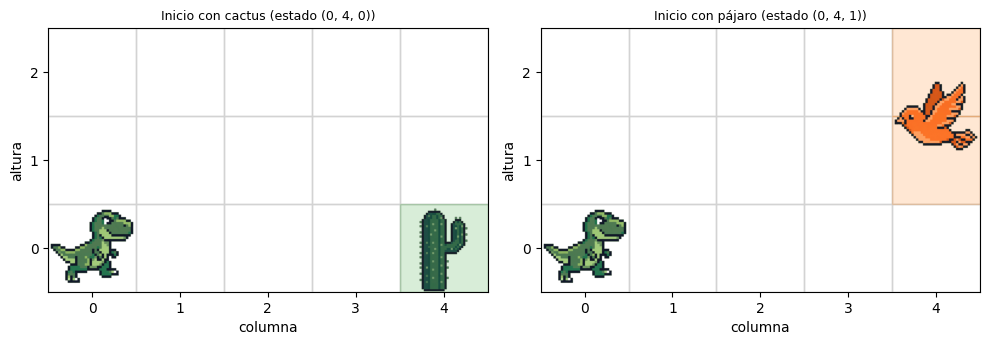

In [102]:
import os   # para armar las rutas de los archivos de imagen

CARPETA_SPRITES = "sprites"   # carpeta con los PNG, junto al notebook
NOMBRES_SPRITES = ["dino_corriendo", "dino_salto", "dino_choque", "cactus", "cactus_mediano", "cactus_chico", "pajaro"]

# Variantes visuales del cactus: (archivo, alto máximo en celdas). Son solo estéticas: todas ocupan la misma
# celda (altura 0) y se esquivan igual, así que no cambian las reglas ni lo que aprende el agente.
CACTUS_VARIANTES = [("cactus", 0.95), ("cactus_mediano", 0.95), ("cactus_chico", 0.71)]


def variante_cactus(n_obstaculo):
    # Elige la variante del cactus nº n_obstaculo de la partida. Usa su propio generador (no el del entorno),
    # así elegir un dibujo no altera los obstáculos ni los resultados; y el mismo n da siempre el mismo dibujo.
    return CACTUS_VARIANTES[random.Random(n_obstaculo).randrange(len(CACTUS_VARIANTES))]


def cargar_sprites(carpeta=CARPETA_SPRITES):
    # Lee los PNG. Devuelve un diccionario {nombre: imagen}; si un archivo falta, su valor es None
    # y dibujar_fotograma() usa rectángulos de colores en su lugar.
    sprites = {}
    for nombre in NOMBRES_SPRITES:
        try:
            sprites[nombre] = plt.imread(os.path.join(carpeta, nombre + ".png"))   # matriz RGBA con valores 0 a 1
        except FileNotFoundError:
            sprites[nombre] = None
    faltan = [n for n, img in sprites.items() if img is None]
    if faltan:
        print(f"Aviso: no se encontraron {faltan} en la carpeta '{carpeta}/'. Se dibujan rectángulos de colores.")
    else:
        print("Sprites cargados:", ", ".join(sprites))
    return sprites


SPRITES = cargar_sprites()


def poner_sprite(ax, img, cx, cy, ancho_max, alto_max, zorder=3):
    # Dibuja la imagen centrada en (cx, cy), escalada para entrar en ancho_max x alto_max sin deformarse.
    alto_px, ancho_px = img.shape[:2]
    escala = min(ancho_max / ancho_px, alto_max / alto_px)
    w, h = ancho_px * escala, alto_px * escala
    ax.imshow(img, extent=(cx - w / 2, cx + w / 2, cy - h / 2, cy + h / 2), zorder=zorder)


def dibujar_fotograma(ax, estado, choque=False, titulo="", n_obstaculo=0):
    # Dibuja un estado (fase, distancia, tipo) como grilla de 5 columnas x 3 alturas en el eje ax.
    # n_obstaculo: cuántos obstáculos esquivó ya el dino; sirve solo para elegir la variante visual del cactus.
    fase, distancia, tipo = estado

    # Las 15 celdas de la grilla
    for col in range(5):
        for altura in range(3):
            ax.add_patch(Rectangle((col - 0.5, altura - 0.5), 1, 1, fill=False, edgecolor="lightgray", zorder=1))

    # Obstáculo: cuadro semitransparente en las celdas que ocupa (zona de choque) + su imagen
    color_obs = "tab:green" if tipo == CACTUS else "tab:orange"
    for altura in OCUPA[tipo]:
        ax.add_patch(Rectangle((distancia - 0.5, altura - 0.5), 1, 1, color=color_obs, alpha=0.18, zorder=2))
    if tipo == CACTUS:
        nombre_cactus, alto_cactus = variante_cactus(n_obstaculo)
        img_obs = SPRITES.get(nombre_cactus) if SPRITES.get(nombre_cactus) is not None else SPRITES["cactus"]
    else:
        img_obs = SPRITES["pajaro"]
    if img_obs is not None:
        if tipo == CACTUS:
            poner_sprite(ax, img_obs, distancia, -0.5 + alto_cactus / 2, 0.9, alto_cactus)   # apoyado en el piso de la celda
        else:
            poner_sprite(ax, img_obs, distancia, 1.5, 0.95, 1.6)        # centrado entre las alturas 1 y 2
    else:                                                               # respaldo sin imagen
        for altura in OCUPA[tipo]:
            ax.add_patch(Rectangle((distancia - 0.4, altura - 0.4), 0.8, 0.8, color=color_obs, zorder=3))

    # Dino: siempre en la columna 0, a la altura que marca su fase.
    # Imagen según la situación: choque, en el suelo (corriendo) o en el aire (salto).
    altura_dino = ALTURA_SEGUN_FASE[fase]
    nombre_dino = "dino_choque" if choque else ("dino_corriendo" if fase == 0 else "dino_salto")
    img_dino = SPRITES[nombre_dino]
    if img_dino is not None:
        poner_sprite(ax, img_dino, 0, altura_dino, 0.95, 0.95, zorder=4)
    else:                                                               # respaldo sin imagen
        ax.add_patch(Rectangle((-0.4, altura_dino - 0.4), 0.8, 0.8,
                               color="tab:red" if choque else "tab:blue", zorder=4))

    # Ejes (se fijan al final porque imshow cambia los límites)
    ax.set_xlim(-0.5, 4.5); ax.set_ylim(-0.5, 2.5); ax.set_aspect("equal")
    ax.set_xticks(range(5)); ax.set_yticks(range(3))
    ax.set_xlabel("columna"); ax.set_ylabel("altura")
    ax.set_title(titulo, fontsize=9)


# Los dos tipos de obstáculo recién aparecidos, con el dino en el suelo
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6))
dibujar_fotograma(ejes[0], (0, 4, CACTUS), titulo="Inicio con cactus (estado (0, 4, 0))")
dibujar_fotograma(ejes[1], (0, 4, PAJARO), titulo="Inicio con pájaro (estado (0, 4, 1))")
plt.tight_layout(); plt.show()

## 4. Espacio de estados y de acciones

Listamos explícitamente los 32 estados y comprobamos, jugando al azar, que **todos se pueden alcanzar**. Si algún estado fuera inalcanzable, la tabla Q de la Parte 2 tendría filas que nunca se aprenden.
También armamos la conversión estado ↔ número (0 a 31), que usará la tabla Q como índice de fila.

In [103]:
N_ESTADOS = 4 * 4 * 2   # fase (4) x distancia (4) x tipo (2)

def estado_a_indice(estado):
    # Convierte (fase, distancia, tipo) en un número de 0 a 31 (fila de la tabla Q).
    fase, distancia, tipo = estado
    return fase * 8 + (distancia - 1) * 2 + tipo

def indice_a_estado(i):
    # Operación inversa de estado_a_indice.
    return i // 8, (i % 8) // 2 + 1, i % 2

# Los 32 estados posibles
todos = [(f, d, t) for f in range(4) for d in range(1, 5) for t in (CACTUS, PAJARO)]
assert len(todos) == N_ESTADOS
# La conversión es biyectiva: 32 estados <-> 32 índices distintos, y es reversible
assert sorted(estado_a_indice(e) for e in todos) == list(range(N_ESTADOS))
assert all(indice_a_estado(estado_a_indice(e)) == e for e in todos)

# Jugamos 200 partidas con acciones al azar y anotamos todos los estados que aparecen
env = DinoEnv(semilla=0)
azar_exploracion = random.Random(0)
vistos = set()
for _ in range(200):
    estado, fin = env.reset(), False
    while not fin:
        vistos.add(estado)
        estado, r, terminado, truncado, info = env.step(azar_exploracion.choice([NADA, SALTAR]))
        fin = terminado or truncado

print(f"Estados posibles: {N_ESTADOS} | alcanzados jugando al azar: {len(vistos)}")
assert vistos == set(todos), "hay estados inalcanzables"

# Cuántos de esos estados permiten una decisión real: solo los que tienen al dino en el suelo (fase 0)
decisiones = [e for e in todos if e[0] == 0]
print(f"Estados donde la acción importa (dino en el suelo): {len(decisiones)} de {N_ESTADOS}")

Estados posibles: 32 | alcanzados jugando al azar: 32
Estados donde la acción importa (dino en el suelo): 8 de 32


## 5. Pruebas del entorno

Probamos cada regla por separado. Si alguna falla, `assert` corta y muestra cuál. Cada prueba verifica una regla de la Entrega 1:

- arranque en el suelo y con el obstáculo en la columna 4,
- el cactus se esquiva en el aire (saltar con el cactus a distancia 1, 2 o 3) y se choca en el suelo; saltar a distancia 4 es demasiado temprano,
- el pájaro se esquiva en el suelo y se choca si se salta a distancia 1, 2 o 3,
- en el aire la acción no cambia nada,
- los valores de recompensa coinciden con la tabla de la Entrega 1,
- la recompensa total máxima de un episodio es 420 y el tope termina con *truncado* (no con *terminado*).

`jugar()` arma una partida con el obstáculo que queramos y le pasa una lista de acciones.

In [104]:
def jugar(tipo, acciones, recompensas=RECOMPENSAS):
    # Arma una partida con un obstáculo de tipo dado y ejecuta la lista de acciones.
    # Devuelve el primer evento que no sea "nada" (choque o esquivó) con su recompensa.
    env = DinoEnv(recompensas, semilla=0)
    env.reset()
    env.tipo = tipo                       # forzamos el tipo para probar cada caso
    for a in acciones:
        estado, r, terminado, truncado, info = env.step(a)
        if info["evento"] != "nada":
            return info["evento"], r
    return "nada", r


# --- Arranque: en el suelo, obstáculo en la columna 4, sin esquivados
env = DinoEnv(semilla=0)
estado_inicial = env.reset()
assert estado_inicial[:2] == (0, 4) and env.esquivados == 0

# --- Cactus: si no salta, choca. Si salta con el cactus a 1, 2 o 3 columnas, lo esquiva
assert jugar(CACTUS, [NADA] * 4) == ("choque", -100)
for d in (1, 2, 3):
    acciones = [NADA] * (4 - d) + [SALTAR] + [NADA] * 4    # espera hasta distancia d y salta
    assert jugar(CACTUS, acciones) == ("esquivó", 11), d
# A distancia 4 salta demasiado temprano: cae al suelo justo cuando llega el cactus
assert jugar(CACTUS, [SALTAR] + [NADA] * 3) == ("choque", -100)

# --- Pájaro: al revés. Quedarse en el suelo lo esquiva, saltar a 1, 2 o 3 columnas lo hace chocar
assert jugar(PAJARO, [NADA] * 4) == ("esquivó", 11)
for d in (1, 2, 3):
    assert jugar(PAJARO, [NADA] * (4 - d) + [SALTAR] + [NADA] * 4) == ("choque", -100), d
# Saltar a distancia 4 también esquiva al pájaro: cuando llega, el dino ya aterrizó
assert jugar(PAJARO, [SALTAR] + [NADA] * 3) == ("esquivó", 11)

# --- En el aire la acción no cambia nada: saltar o no hacer nada da las mismas fases
fases = []
for a in (NADA, SALTAR):
    env = DinoEnv(semilla=0)
    env.reset()
    env.step(SALTAR)                      # empieza un salto
    env.step(a)                           # estando en el aire, a no debería importar
    fases.append(env.fase)
assert fases[0] == fases[1] == 2

# --- Recompensas parametrizables: el entorno usa los valores que se le pasan
assert jugar(CACTUS, [NADA] * 4, {"paso": 0, "esquivar": 0, "choque": -7}) == ("choque", -7)

# --- Tope: con una regla escrita a mano ("saltar si hay un cactus a 1 columna") esquiva todo.
#     Esto prueba que ningún obstáculo es imposible: si el agente choca, es culpa de su decisión, no del entorno.
env = DinoEnv(semilla=1)
estado, total, pasos, fin = env.reset(), 0, 0, False
while not fin:
    fase, distancia, tipo = estado
    accion = SALTAR if (fase == 0 and tipo == CACTUS and distancia == 1) else NADA
    estado, r, terminado, truncado, info = env.step(accion)
    total, pasos, fin = total + r, pasos + 1, terminado or truncado
# 30 obstáculos, 120 pasos, 120*1 + 30*10 = 420, termina por tope (truncado) y no por choque (terminado)
assert (env.esquivados, pasos, total, terminado, truncado) == (30, 120, 420, False, True)

print("Todas las pruebas pasaron")

Todas las pruebas pasaron


## 6. Una partida dibujada

La regla a mano ("saltar solo si hay un cactus a 1 columna"), paso a paso, en texto y en gráficos. `D` es el dino, `C` el cactus, `P` el pájaro.

. . . . . 
. . . . . 
D . . . C 

Paso 1: nada -> recompensa 1 (nada)
. . . . . 
. . . . . 
D . . C . 

Paso 2: nada -> recompensa 1 (nada)
. . . . . 
. . . . . 
D . C . . 

Paso 3: nada -> recompensa 1 (nada)
. . . . . 
. . . . . 
D C . . . 

Paso 4: saltar -> recompensa 11 (esquivó)
. . . . . 
D . . . . 
. . . . C 

Paso 5: nada -> recompensa 1 (nada)
D . . . . 
. . . . . 
. . . C . 

Paso 6: nada -> recompensa 1 (nada)
. . . . . 
D . . . . 
. . C . . 

Paso 7: nada -> recompensa 1 (nada)
. . . . . 
. . . . . 
D C . . . 

Paso 8: saltar -> recompensa 11 (esquivó)
. . . . P 
D . . . P 
. . . . . 



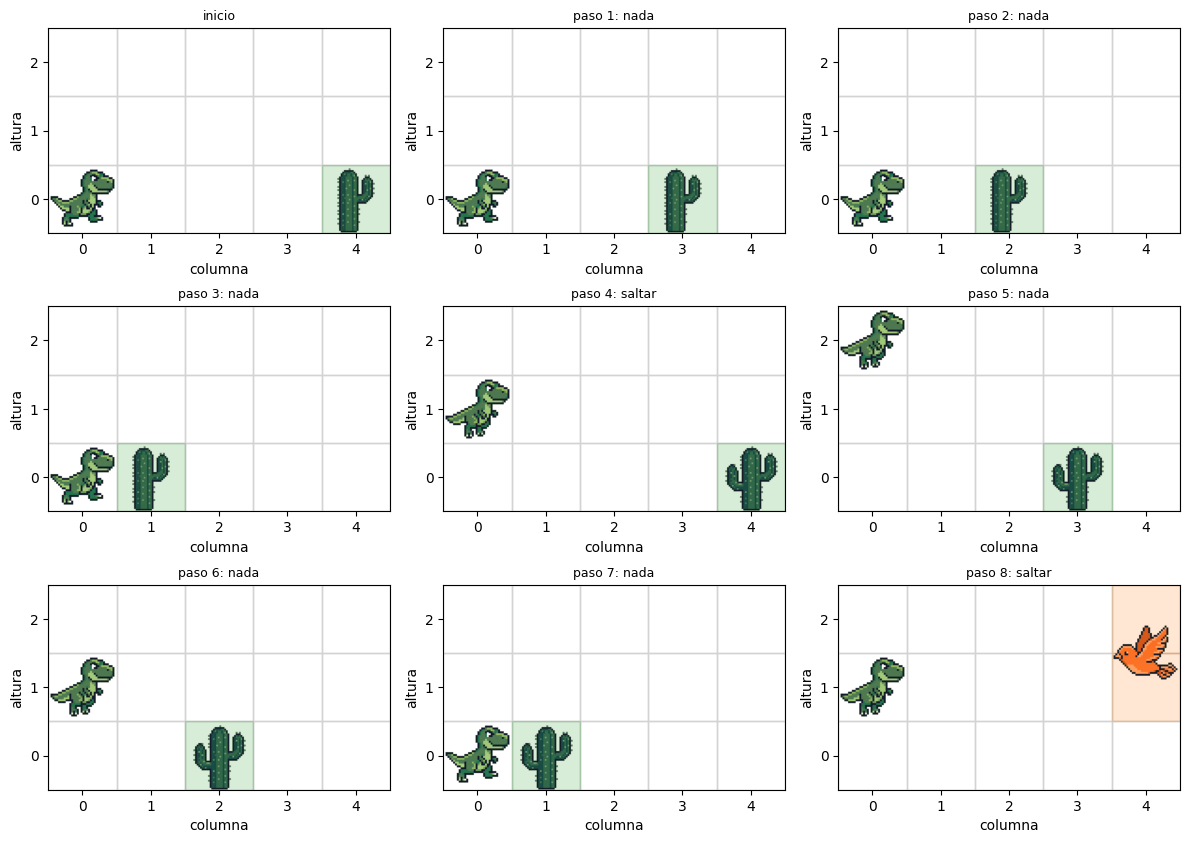

In [105]:
# Regla a mano: función estado -> acción. Sirve para probar el entorno y después como referencia (línea base).
def regla_a_mano(estado):
    fase, distancia, tipo = estado
    return SALTAR if (fase == 0 and tipo == CACTUS and distancia == 1) else NADA


env = DinoEnv(semilla=3)
estado = env.reset()
env.render()                                         # estado inicial en texto
estados_partida = [(estado, False, "inicio", 0)]        # guardamos cada fotograma para dibujarlo abajo
for paso in range(8):
    accion = regla_a_mano(estado)
    estado, r, terminado, truncado, info = env.step(accion)
    print(f"Paso {paso + 1}: {NOMBRE_ACCION[accion]} -> recompensa {r} ({info['evento']})")
    env.render()
    estados_partida.append((estado, info["evento"] == "choque",
                            f"paso {paso + 1}: {NOMBRE_ACCION[accion]}", env.esquivados))

# Los mismos 9 fotogramas, dibujados
fig, ejes = plt.subplots(3, 3, figsize=(12, 8.5))
for ax, (est, choque, titulo, n_obs) in zip(ejes.flat, estados_partida):
    dibujar_fotograma(ax, est, choque, titulo, n_obstaculo=n_obs)
plt.tight_layout(); plt.show()

## 7. Líneas base: agente al azar y regla a mano

Antes de entrenar, medimos dos agentes de referencia con 1000 partidas cada uno. Son lo que va a usar la Parte 2 para comparar:
- **Al azar** (el piso): elige saltar o no con probabilidad 50 %. Cualquier agente que aprenda tiene que ganarle por mucho.
- **Regla a mano** (el techo): esquiva siempre los 30 obstáculos. Muestra que el entorno se puede resolver por completo.

Métricas: obstáculos esquivados por episodio, recompensa total por episodio y proporción de episodios que llegan al tope de 30.
`jugar_episodio()` y `evaluar()` son funciones generales: reciben una *política* (una función `estado -> acción`) y la prueban en el entorno.

In [106]:
def jugar_episodio(env, politica):
    # Juega un episodio completo con una política (función estado -> acción).
    # Devuelve: recompensa total, obstáculos esquivados, pasos jugados.
    estado, total, pasos, fin = env.reset(), 0, 0, False
    while not fin:
        estado, r, terminado, truncado, info = env.step(politica(estado))
        total, pasos, fin = total + r, pasos + 1, terminado or truncado
    return total, env.esquivados, pasos


def evaluar(politica, episodios=1000, semilla=42, recompensas=RECOMPENSAS):
    # Juega varios episodios y devuelve los promedios. La semilla fija permite comparar políticas
    # en las mismas condiciones y repetir los resultados.
    env = DinoEnv(recompensas, semilla=semilla)
    res = np.array([jugar_episodio(env, politica) for _ in range(episodios)])
    recompensa, esquivados, pasos = res[:, 0], res[:, 1], res[:, 2]
    return {"recompensa": recompensa.mean(),
            "esquivados": esquivados.mean(),
            "pasos": pasos.mean(),
            "tasa_tope": (esquivados == TOPE_OBSTACULOS).mean(),   # fracción de partidas perfectas
            "mejor": int(esquivados.max())}


# El agente al azar usa su propio generador, separado del del entorno
azar = random.Random(7)
politica_azar = lambda estado: azar.choice([NADA, SALTAR])

linea_base = {"azar": evaluar(politica_azar), "regla a mano": evaluar(regla_a_mano)}
for nombre, m in linea_base.items():
    print(f"{nombre:13s} | esquiva {m['esquivados']:5.2f} de 30 | recompensa {m['recompensa']:6.1f} | "
          f"llega al tope en {m['tasa_tope']:.0%} | mejor episodio: {m['mejor']} obstáculos")

azar          | esquiva  1.02 de 30 | recompensa  -82.7 | llega al tope en 0% | mejor episodio: 9 obstáculos
regla a mano  | esquiva 30.00 de 30 | recompensa  420.0 | llega al tope en 100% | mejor episodio: 30 obstáculos


### Cierre de la Parte 1
El entorno cumple todo lo de la Entrega 2: grilla, 32 estados (todos alcanzables), 2 acciones, función de recompensas, inicio y fin de episodio, y pruebas que pasan. Las líneas base muestran que el problema tiene sentido: al azar casi no esquiva nada (≈ 1 de 30) y una regla simple lo resuelve por completo (30 de 30, recompensa 420).

---
# PARTE 2 – ENTREGA 3: Modelado y análisis

Usa el entorno `DinoEnv` y las funciones de la Parte 1 (hay que haber corrido esa parte antes).

**Consigna de la Entrega 3 (Opción B)** y dónde se cumple cada punto:

| Punto de la consigna | Sección |
|---|---|
| Implementar y entrenar el agente | 8 y 9 |
| Ejecutar múltiples episodios de aprendizaje | 9 (3000 episodios × 10 semillas) |
| Analizar cómo evoluciona el comportamiento del agente | 8.2 (pantalla en vivo) y 10 |
| Representar gráficamente sus movimientos | 8.2 (pantalla en vivo) y 12 |
| Analizar la evolución de la recompensa durante el entrenamiento | 9 |
| Visualizar la estrategia o política aprendida | 11 |
| Modificar la función de recompensa y analizar cómo afecta al agente | 13 |
| (Extra) Sensibilidad a los hiperparámetros | 14 |
| (Extra) Mejoras de exploración para aprender toda la tabla Q | 8.1 y 14.1 |
| Fundamentar las decisiones y relacionar resultados con el problema | texto de cada sección y 15 |

## 8. El agente Q-Learning

**Idea.** El agente tiene una tabla `Q` de 32 filas (estados) × 2 columnas (acciones). `Q[s, a]` estima cuánta recompensa total va a juntar si en el estado `s` hace la acción `a` y después juega lo mejor posible. Arranca en cero. Después de cada paso corrige solo la celda que usó:

`Q(s,a) ← Q(s,a) + α · [ r + γ · max Q(s',·) − Q(s,a) ]`

- `α` (tasa de aprendizaje): cuánto se corrige el valor viejo en cada paso.
- `γ` (descuento): cuánto valen las recompensas futuras frente a las inmediatas.
- `max Q(s',·)`: el valor de lo mejor que se puede hacer desde el estado siguiente.

**Decisiones de diseño y su justificación:**
- **Terminado vs. truncado.** Si el dino choca, el objetivo es solo `r`: después del choque no hay futuro. Si la partida se corta por el tope de 30 obstáculos, el juego *podría* seguir, así que igual sumamos `γ · max Q(s',·)`. Tratar el tope como un final enseñaría, falsamente, que ese estado es "malo".
- **Exploración ε-greedy con decaimiento por episodio.** Con probabilidad `ε` el agente elige una acción al azar (explora) y si no, la mejor según la tabla (explota). `ε` empieza en 1 (todo al azar) y baja ×0,995 por episodio hasta 0,01 (unos 920 episodios). Sin explorar, nunca descubriría que saltar a tiempo evita el choque.
- **Desempate al azar** cuando dos acciones valen igual (por ejemplo, al principio, con la tabla en cero). Sin esto, `argmax` elegiría siempre "nada" y el agente tardaría en probar saltar.
- **Se cuentan visitas** por celda para poder revisar después si la tabla se aprendió con suficientes datos.

In [107]:
# Valores iniciales de los hiperparámetros (los de la Entrega 1)
HIPERPARAMETROS = {
    "alfa": 0.1,          # tasa de aprendizaje
    "gamma": 0.99,        # descuento: alto, porque el castigo de un mal salto llega unos pasos después
    "eps_ini": 1.0,       # al principio explora siempre
    "eps_min": 0.01,      # piso de exploración
    "decaimiento": 0.995, # epsilon se multiplica por esto al final de cada episodio
}
EPISODIOS = 3000          # episodios de entrenamiento


class AgenteQ:
    # Agente Q-Learning tabular.

    def __init__(self, alfa, gamma, eps_ini, eps_min, decaimiento, semilla=None):
        self.alfa, self.gamma = alfa, gamma
        self.eps, self.eps_min, self.decaimiento = eps_ini, eps_min, decaimiento
        self.Q = np.zeros((N_ESTADOS, 2))                  # tabla Q: 32 estados x 2 acciones, todo en cero
        self.visitas = np.zeros((N_ESTADOS, 2), dtype=int) # cuántas veces se actualizó cada celda
        self.azar = random.Random(semilla)                 # generador propio del agente

    def mejor_accion(self, estado):
        # Acción con mayor Q en este estado. Si empatan, elige una al azar.
        q = self.Q[estado_a_indice(estado)]
        if q[0] == q[1]:
            return self.azar.choice([NADA, SALTAR])
        return int(np.argmax(q))

    def elegir(self, estado):
        # Política ε-greedy usada durante el entrenamiento.
        # self.exploro guarda si la última acción fue al azar (lo usa la pantalla en vivo de la sección 8.2).
        self.exploro = self.azar.random() < self.eps
        if self.exploro:
            return self.azar.choice([NADA, SALTAR])        # explora
        return self.mejor_accion(estado)                   # explota

    def aprender(self, estado, accion, r, estado_sig, terminado):
        # Regla de actualización de Q-Learning para una transición (s, a, r, s').
        s, s2 = estado_a_indice(estado), estado_a_indice(estado_sig)
        # Si chocó (terminado) no hay futuro: el objetivo es solo r. El truncado SÍ tiene futuro.
        objetivo = r if terminado else r + self.gamma * self.Q[s2].max()
        self.Q[s, accion] += self.alfa * (objetivo - self.Q[s, accion])
        self.visitas[s, accion] += 1

    def fin_episodio(self):
        # Baja epsilon un poco al terminar cada episodio, sin pasar del piso.
        self.eps = max(self.eps_min, self.eps * self.decaimiento)

    def politica(self, estado):
        # Política final: sin exploración, siempre la mejor acción según la tabla.
        return self.mejor_accion(estado)


def jugar_y_aprender(env, agente):
    # Juega UN episodio completo con exploración y va corrigiendo la tabla Q paso a paso.
    # Devuelve (recompensa total, pasos). Es el ciclo agente-entorno: decide, el entorno responde, aprende.
    estado, total, pasos, fin = env.reset(), 0, 0, False
    while not fin:
        accion = agente.elegir(estado)                                      # 1) decide
        estado_sig, r, terminado, truncado, info = env.step(accion)         # 2) el entorno responde
        agente.aprender(estado, accion, r, estado_sig, terminado)           # 3) corrige su tabla
        estado, total, pasos, fin = estado_sig, total + r, pasos + 1, terminado or truncado
    return total, pasos


def entrenar(recompensas=RECOMPENSAS, episodios=EPISODIOS, semilla=0, guardar_en=(), **hiper):
    # Entrena un agente nuevo. Devuelve (agente, historial).
    #   recompensas: función de recompensa del entorno (se cambia en la sección 13)
    #   guardar_en:  episodios en los que se guarda una copia de la tabla Q (para ver la evolución)
    #   **hiper:     hiperparámetros que se quieren cambiar respecto de HIPERPARAMETROS
    params = {**HIPERPARAMETROS, **hiper}
    env = DinoEnv(recompensas, semilla=semilla)
    agente = AgenteQ(semilla=semilla + 1000, **params)
    hist = {"recompensa": [], "esquivados": [], "pasos": [], "epsilon": []}
    agente.copias = {}                                     # {episodio: copia de Q en ese momento}

    for ep in range(episodios + 1):
        if ep in guardar_en:
            agente.copias[ep] = agente.Q.copy()
        if ep == episodios:
            break
        total, pasos = jugar_y_aprender(env, agente)                        # un episodio completo
        hist["recompensa"].append(total)                                    # lo anotado en este episodio
        hist["esquivados"].append(env.esquivados)
        hist["pasos"].append(pasos)
        hist["epsilon"].append(agente.eps)
        agente.fin_episodio()
    return agente, {k: np.array(v) for k, v in hist.items()}

### Funciones auxiliares

Dos funciones que usan esta sección y las siguientes:
- `politica_desde_Q(Q)`: convierte una tabla Q en una política que siempre elige la mejor acción (sin exploración).
- `grabar_episodio()`: juega un episodio con una política y guarda todo lo necesario para dibujarlo.

In [108]:
def politica_desde_Q(Q):
    # Política greedy (sin exploración) a partir de una tabla Q guardada.
    # Con empate elige NADA, para que la partida sea siempre la misma (y la tabla vacía = "nunca salta").
    return lambda estado: int(np.argmax(Q[estado_a_indice(estado)]))


def grabar_episodio(politica, semilla, max_pasos=120, recompensas=RECOMPENSAS):
    # Juega un episodio y guarda todo lo necesario para dibujarlo.
    # Devuelve: lista de alturas del dino, lista de (paso, tipo, evento) cuando un obstáculo llega,
    #           lista de acciones, y lista de estados (para los fotogramas).
    env = DinoEnv(recompensas, semilla=semilla)
    estado, fin, paso = env.reset(), False, 0
    alturas, llegadas, acciones, estados = [], [], [], [estado]
    while not fin and paso < max_pasos:
        a = politica(estado)
        tipo_obstaculo = estado[2]                            # el tipo del obstáculo que se está enfrentando
        estado, r, terminado, truncado, info = env.step(a)
        alturas.append(ALTURA_SEGUN_FASE[env.fase])           # altura del dino después de moverse
        acciones.append(a)
        estados.append(estado)
        if info["evento"] != "nada":                          # el obstáculo llegó: esquivó o chocó
            llegadas.append((paso, tipo_obstaculo, info["evento"]))
        paso += 1
        fin = terminado or truncado
    return alturas, llegadas, acciones, estados

## 8.1 Mejoras para que aprenda toda la tabla

El agente de la sección 8 aprende a **jugar** perfecto en ~40 episodios, pero eso no quiere decir que haya aprendido **toda la tabla Q**: muchos valores quedan lejos de su valor real, sobre todo los de situaciones que casi no visita (por ejemplo, un cactus a distancia 1 con el dino en el suelo, si siempre salta antes). Para que aprenda más, agregamos cinco mejoras. Ninguna cambia el juego ni las recompensas; solo cambian **cómo explora y cómo corrige** el agente.

| Mejora | Qué cambia | Por qué ayuda |
|---|---|---|
| **A1. Q inicial optimista** | La tabla arranca en **400** en lugar de 0 (un poco más que el valor real más alto, ≈ 354) | Toda acción sin probar parece buena, así que el agente termina probándolas todas. Cada vez que prueba una, su valor baja a la realidad y la otra pasa adelante. |
| **A2. Inicios variados** | El primer obstáculo de cada episodio aparece a distancia 1, 2, 3 o 4 (no siempre a 4) | Lo pone en situaciones a las que su propia política nunca lo llevaría. |
| **A3. Bonus por exploración** | Al elegir, suma `c / √(N(s,a) + 1)` al valor de cada acción (`c = 50`, `N` = visitas) | Prefiere lo que probó poco: una exploración dirigida, no al azar. El bonus solo se usa para **elegir mientras entrena**; la política final usa la tabla Q sola. |
| **A4. α según visitas** | `α = max(0,1 ; 1/N(s,a))`: la 1ª visita usa α = 1, la 2ª α = 0,5, …, y desde la 10ª el α = 0,1 de siempre | Las primeras correcciones son grandes (aprende rápido lo nuevo) y después se estabiliza. Con `α = 1/N` puro los pasos se achican demasiado y la tabla deja de mejorar (lo probamos: queda lejos del valor real). |
| **A5. Explorar más tiempo** | ε baja ×0,998 por episodio (en lugar de ×0,995) y su piso es 0,05 (en lugar de 0,01) | Sigue visitando situaciones raras durante más episodios. |

**¿Cómo sabemos si aprendió "toda la tabla"?** Como conocemos las reglas del juego, podemos calcular la tabla Q **perfecta**, `Q*`, con *iteración de valor* (programación dinámica): se aplica la ecuación de Bellman `Q*(s,a) = Σ p · [r + γ · max Q*(s',·)]` a las 64 celdas, una y otra vez, hasta que no cambia más. **El agente no usa `Q*`** (no conoce las reglas); la usamos nosotros solo para medir. Decimos que una celda está **bien aprendida** si su valor está a menos del 5 % del valor real.

Estas mejoras se usan en la pantalla en vivo (8.2) y se comparan una por una en la sección 14.1. El resto del notebook (secciones 9 a 14) usa el agente base de la sección 8, sin mejoras.

In [109]:
# Valores de las mejoras. Los usan la pantalla en vivo (8.2) y el experimento de la sección 14.1.
MEJORAS = {
    "q_inicial": 400.0,         # A1: un poco más que el valor real más alto (≈ 354): toda acción sin probar parece buena
    "inicio_variado": True,     # A2: el primer obstáculo de cada episodio aparece a distancia 1, 2, 3 o 4
    "bonus": 50.0,              # A3: c del bonus c / √(N + 1) que se suma al elegir
    "alfa_por_visitas": True,   # A4: α = max(0,1 ; 1/N): pasos grandes en las primeras visitas, después el α de siempre
    "eps_min": 0.05,            # A5: piso de ε más alto...
    "decaimiento": 0.998,       # A5: ...y ε baja más lento (×0,998 en lugar de ×0,995)
}


class DinoEnvInicioVariado(DinoEnv):
    # A2: el mismo entorno, pero el primer obstáculo de cada episodio aparece a una distancia al azar (1 a 4).
    def reset(self):
        super().reset()
        self.distancia = self.azar.randint(1, 4)
        return self.estado()


class AgenteQMejorado(AgenteQ):
    # Agente Q-Learning con las mejoras A1, A3 y A4 (A2 está en el entorno y A5 son solo hiperparámetros).
    # Con los valores por defecto se comporta exactamente igual que AgenteQ.

    def __init__(self, alfa, gamma, eps_ini, eps_min, decaimiento, semilla=None,
                 q_inicial=0.0, bonus=0.0, alfa_por_visitas=False):
        super().__init__(alfa, gamma, eps_ini, eps_min, decaimiento, semilla)
        self.Q[:] = q_inicial                       # A1: tabla optimista
        self.bonus = bonus                          # A3: peso del bonus por exploración
        self.alfa_por_visitas = alfa_por_visitas    # A4: α que baja con las visitas
        self.alfa_usado, self.objetivo = alfa, 0.0  # lo usado en la última corrección (lo muestra la pantalla en vivo)

    def elegir(self, estado):
        # ε-greedy, pero al explotar suma el bonus: las acciones poco probadas parecen mejores de lo que dice la tabla.
        self.exploro = self.azar.random() < self.eps
        if self.exploro:
            return self.azar.choice([NADA, SALTAR])                         # explora al azar
        s = estado_a_indice(estado)
        valores = self.Q[s] + self.bonus / np.sqrt(self.visitas[s] + 1)    # A3
        if valores[0] == valores[1]:
            return self.azar.choice([NADA, SALTAR])                         # empate: al azar
        return int(np.argmax(valores))

    def aprender(self, estado, accion, r, estado_sig, terminado):
        # La misma regla de Q-Learning; solo cambia el α que se usa (A4).
        s, s2 = estado_a_indice(estado), estado_a_indice(estado_sig)
        self.visitas[s, accion] += 1
        self.alfa_usado = max(self.alfa, 1 / self.visitas[s, accion]) if self.alfa_por_visitas else self.alfa
        self.objetivo = r if terminado else r + self.gamma * self.Q[s2].max()
        self.Q[s, accion] += self.alfa_usado * (self.objetivo - self.Q[s, accion])


def crear_entorno_y_agente(semilla, tope=TOPE_OBSTACULOS, inicio_variado=False, **opciones):
    # Arma el entorno y el agente con las mejoras pedidas. Sin opciones, es el agente base de la sección 8.
    entorno = (DinoEnvInicioVariado if inicio_variado else DinoEnv)(RECOMPENSAS, tope=tope, semilla=semilla)
    agente = AgenteQMejorado(semilla=semilla + 1000, **{**HIPERPARAMETROS, **opciones})
    return entorno, agente


# ---------- Tabla Q perfecta (Q*), solo para medir cuánto aprendió el agente ----------
def transiciones(estado, accion):
    # Lista de (probabilidad, recompensa, estado siguiente, terminado) para (estado, acción).
    # Usa el propio entorno: lo pone en ese estado y da un paso. El único azar es el tipo del obstáculo nuevo.
    env = DinoEnv(tope=10**9)
    env.reset()
    env.fase, env.distancia, env.tipo = estado
    estado_sig, r, terminado, truncado, info = env.step(accion)
    if info["evento"] == "esquivó":                      # aparece un obstáculo nuevo: 50 % cactus, 50 % pájaro
        return [(0.5, r, (estado_sig[0], estado_sig[1], t), False) for t in (CACTUS, PAJARO)]
    return [(1.0, r, estado_sig, terminado)]


def q_optima(gamma=HIPERPARAMETROS["gamma"]):
    # Iteración de valor: aplica la ecuación de Bellman a las 64 celdas hasta que la tabla deja de cambiar.
    modelo = {(s, a): transiciones(indice_a_estado(s), a) for s in range(N_ESTADOS) for a in (NADA, SALTAR)}
    Q = np.zeros((N_ESTADOS, 2))
    while True:
        nueva = np.zeros_like(Q)
        for (s, a), salidas in modelo.items():
            nueva[s, a] = sum(p * (r + (0 if fin else gamma * Q[estado_a_indice(s2)].max())) for p, r, s2, fin in salidas)
        if np.abs(nueva - Q).max() < 1e-6:
            return nueva
        Q = nueva


def celdas_bien_aprendidas(Q):
    # Cuántas de las 64 celdas están a menos del 5 % de su valor real (+1 de margen para los valores cercanos a 0).
    return int((np.abs(Q - Q_OPTIMA) <= 0.05 * np.abs(Q_OPTIMA) + 1).sum())


Q_OPTIMA = q_optima()
print("Tabla Q perfecta (Q*) en las 8 decisiones con el dino en el suelo:")
print(f"{'obstáculo':10s} {'dist':>4s} {'Q*(nada)':>9s} {'Q*(saltar)':>11s}  mejor acción")
for tipo in (CACTUS, PAJARO):
    for d in (4, 3, 2, 1):
        q = Q_OPTIMA[estado_a_indice((0, d, tipo))]
        mejor = "indiferente" if abs(q[0] - q[1]) < 1 else NOMBRE_ACCION[int(np.argmax(q))]
        print(f"{NOMBRE_TIPO[tipo]:10s} {d:4d} {q[0]:9.1f} {q[1]:11.1f}  {mejor}")

# Con las opciones por defecto, el agente "mejorado" es idéntico al de la sección 8 (misma tabla, mismas decisiones)
env_prueba, agente_prueba = crear_entorno_y_agente(semilla=0)
for _ in range(50):
    jugar_y_aprender(env_prueba, agente_prueba); agente_prueba.fin_episodio()
assert np.array_equal(agente_prueba.Q, entrenar(semilla=0, episodios=50)[0].Q)
print("\nComprobado: sin mejoras, AgenteQMejorado aprende exactamente lo mismo que AgenteQ.")

Tabla Q perfecta (Q*) en las 8 decisiones con el dino en el suelo:
obstáculo  dist  Q*(nada)  Q*(saltar)  mejor acción
cactus        4     346.2       -94.1  nada
cactus        3     348.7       348.7  indiferente
cactus        2     351.2       351.2  indiferente
cactus        1    -100.0       353.8  saltar
pájaro        4     346.2       346.2  indiferente
pájaro        3     348.7       -96.0  nada
pájaro        2     351.2       -98.0  nada
pájaro        1     353.8      -100.0  nada

Comprobado: sin mejoras, AgenteQMejorado aprende exactamente lo mismo que AgenteQ.


## 8.2 Entrenamiento en vivo: la pantalla del juego

Acá se ve **todo el entrenamiento del agente, episodio por episodio y paso por paso, sin saltear nada**, como un juego de verdad, junto con **todo lo que pasa adentro del agente**: su tabla Q, las visitas, el α que usa, ε y la cuenta exacta de cada corrección. El agente tiene las cinco mejoras de la sección 8.1.

**Cómo funciona.** La celda de abajo entrena un agente nuevo y graba *cada* paso de *cada* episodio: qué hizo el dino, por qué eligió esa acción, qué recompensa recibió y cómo corrigió su tabla. Después muestra un **reproductor** que pasa toda esa grabación en orden, con movimiento suave. Está hecho en HTML/JavaScript, así que funciona igual en Colab, en Jupyter y en VS Code.

**Qué hay en la pantalla:**
- **Arriba a la izquierda – el juego.** El episodio en curso, con esquivados y recompensa acumulada. Debajo:
  - **Acción** y **por qué la eligió**: *al azar (explorando)*, *según su tabla Q*, *por el bonus de exploración* (A3: la otra acción la probó menos) o *empate en la tabla*. En el aire la acción no cambia nada.
  - **Lo que aprendió en ese paso**: qué celda corrigió, cuántas veces la visitó, el **α** usado (A4: 1, 0,5, 0,33… hasta 0,1) y la cuenta completa `Q ← Q + α · (objetivo − Q)` con los números.
- **Abajo a la izquierda – la tabla Q completa** (32 estados × 2 acciones = 64 celdas). Gris = nunca probada; verde = bien aprendida (a menos del 5 % del valor real `Q*`); amarillo → rojo = todavía lejos. Arriba cuenta cuántas de las 64 están bien.
- **Arriba a la derecha – evolución por episodio.** Barras: obstáculos esquivados. Línea naranja: ε. Línea violeta: α promedio del episodio.
- **Abajo a la derecha – las 8 decisiones** (dino en el suelo). Para cada acción: su valor `Q`, las visitas `N` y el valor real `Q*`. En verde la acción que hoy elegiría; con borde amarillo la celda que acaba de corregir; con ▶ la situación en la que está ahora. La última columna dice si la decisión coincide con la de `Q*` (✓) o no (✗).

**Controles:** ▶ / ⏸, ⟲ para empezar de nuevo y la velocidad (no saltea pasos: solo los pasa más rápido).

**Qué se va a ver.** Al principio toda la tabla vale 400 (A1) y el agente prueba de todo: casi todo es al azar y choca enseguida, pero cada choque baja de golpe el valor de la acción que lo causó (con α = 1 en la primera visita). Las celdas pasan de gris a amarillo y rojo, y los valores van bajando hacia `Q*`. Cuando ε baja, empieza a saltar los cactus a tiempo y a quedarse quieto con los pájaros, hasta esquivar los 10 obstáculos. Algunos choques tardíos se deben a la exploración que queda (ε nunca baja de 0,05).

**Diferencias con el entrenamiento de la sección 9 (y por qué).** Para que el proceso completo entre en unos minutos de pantalla:
- cada partida termina a los **10 obstáculos** en lugar de 30,
- son **80 episodios** en lugar de 3000,
- ε baja más rápido (**×0,95** por episodio en lugar de ×0,998 de las mejoras).

En 80 episodios el agente ya **decide** bien en las 8 situaciones, pero los valores todavía no llegaron a `Q*`: para eso hacen falta cientos de episodios más (sección 14.1). `EN_VIVO = False` saltea esta celda.

Grabados 80 episodios y 1945 pasos. Esquivados por episodio: [0, 1, 3, 3, 2, 3, 0, 0, 1, 6, 2, 1, 1, 0, 2, 7, 1, 0, 4, 2, 7, 0, 1, 3, 10, 9, 10, 10, 1, 1, 3, 0, 3, 2, 2, 8, 10, 6, 10, 2, 2, 10, 10, 10, 10, 10, 0, 10, 10, 1, 6, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 4, 8, 10, 10, 10, 10, 10, 10, 10, 8, 10, 10, 6, 10, 6, 10, 1, 10, 3]
Al terminar: 10 de 64 celdas bien aprendidas.



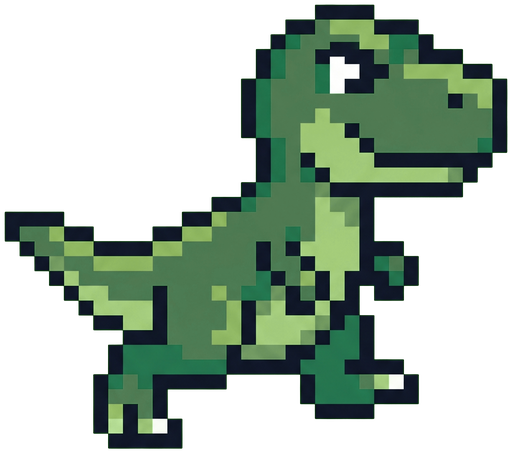
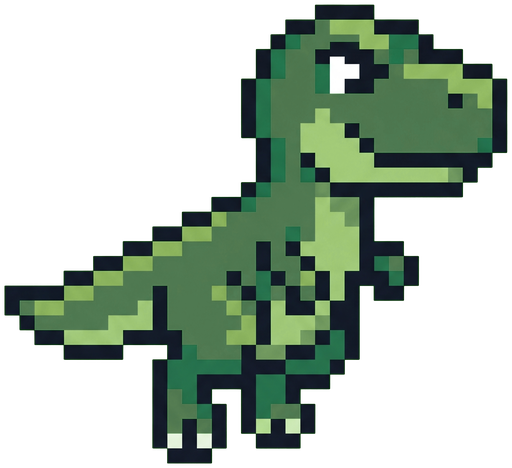
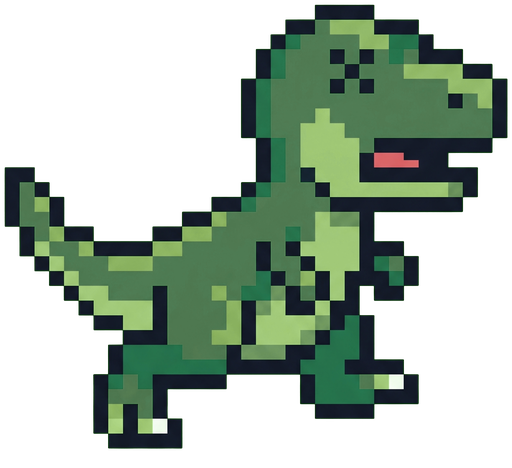
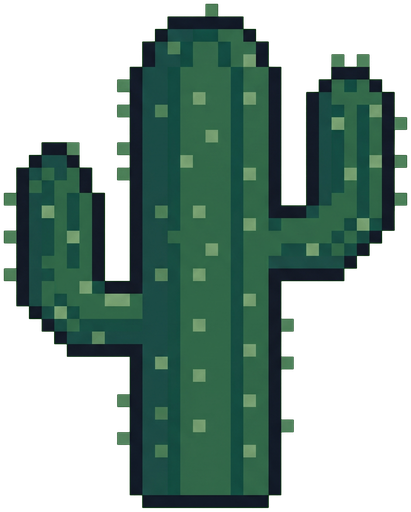
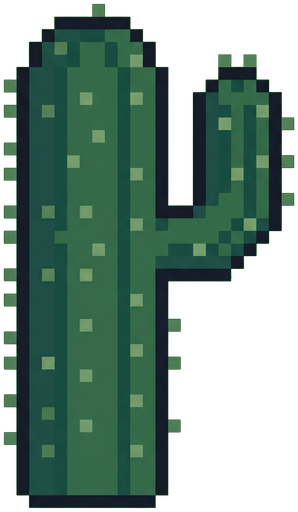
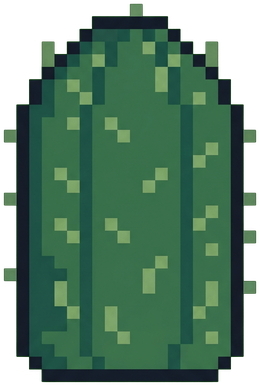
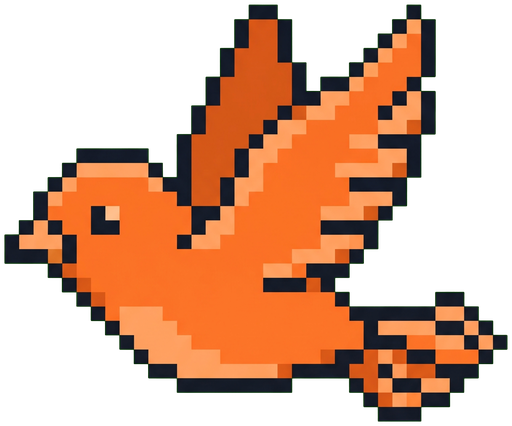

In [110]:
import base64, json                       # para meter los datos y las imágenes dentro del reproductor HTML
from IPython.display import HTML, display  # para mostrar el reproductor en el notebook

EN_VIVO = True                 # False = saltear la pantalla en vivo
EPISODIOS_EN_VIVO = 80         # se muestran TODOS: no se saltea ninguno
TOPE_EN_VIVO = 10              # obstáculos por partida en la pantalla
MEJORAS_EN_VIVO = {**MEJORAS, "decaimiento": 0.95}   # las mismas mejoras; ε baja más rápido para que entre en pocos minutos
MS_POR_PASO = 260              # duración de un paso a velocidad 1x (milisegundos)
EVENTO_A_CODIGO = {"nada": 0, "esquivó": 1, "choque": 2}


def origen_de_la_accion(agente, accion, q_antes, n_antes):
    # Por qué eligió esa acción: 0 = al azar (ε), 1 = la mejor según su tabla Q,
    # 2 = la eligió el bonus de exploración (sin bonus habría elegido otra o habría empate), 3 = empate (al azar).
    if agente.exploro:
        return 0
    valores = q_antes + agente.bonus / np.sqrt(n_antes + 1)
    if valores[0] == valores[1]:
        return 3
    if q_antes[0] == q_antes[1] or int(np.argmax(q_antes)) != accion:
        return 2
    return 1


def grabar_entrenamiento(episodios=EPISODIOS_EN_VIVO, tope=TOPE_EN_VIVO, opciones=MEJORAS_EN_VIVO, semilla=0):
    # Entrena un agente nuevo y graba cada paso de cada episodio para poder reproducirlo.
    # Es el mismo ciclo que jugar_y_aprender(), pero anotando todo lo que pasa adentro del agente.
    env, agente = crear_entorno_y_agente(semilla, tope=tope, **opciones)
    grabacion = []
    for ep in range(episodios):
        estado = env.reset()
        registro = {"eps": round(agente.eps, 4), "inicio": list(estado), "pasos": []}
        fin, total = False, 0
        while not fin:
            s = estado_a_indice(estado)
            q_antes, n_antes = agente.Q[s].copy(), agente.visitas[s].copy()     # la tabla con la que decide
            accion = agente.elegir(estado)                                   # 1) decide
            origen = origen_de_la_accion(agente, accion, q_antes, n_antes)
            estado_sig, r, terminado, truncado, info = env.step(accion)      # 2) el entorno responde
            agente.aprender(estado, accion, r, estado_sig, terminado)        # 3) corrige su tabla
            total += r
            # Un paso grabado: acción, origen, estado siguiente, recompensa, evento,
            # y la corrección: celda (estado s), α usado, objetivo y nuevo valor de Q(s, acción)
            registro["pasos"].append([accion, origen, *estado_sig, r, EVENTO_A_CODIGO[info["evento"]],
                                      s, round(agente.alfa_usado, 4), round(agente.objetivo, 2), round(agente.Q[s, accion], 2)])
            estado, fin = estado_sig, terminado or truncado
        registro["esquivados"], registro["total"] = env.esquivados, total
        grabacion.append(registro)
        agente.fin_episodio()
    return agente, grabacion


def sprites_en_base64(carpeta=CARPETA_SPRITES):
    # Convierte cada PNG en texto (data URI) para meterlo dentro del HTML. Si falta, el reproductor dibuja rectángulos.
    resultado = {}
    for nombre in NOMBRES_SPRITES:
        ruta = os.path.join(carpeta, nombre + ".png")
        if os.path.exists(ruta):
            with open(ruta, "rb") as f:
                resultado[nombre] = "data:image/png;base64," + base64.b64encode(f.read()).decode()
    return resultado


def pantalla_en_vivo(grabacion, tope=TOPE_EN_VIVO, opciones=MEJORAS_EN_VIVO):
    # Arma el reproductor HTML/JavaScript con la grabación del entrenamiento.
    params = {**HIPERPARAMETROS, **opciones}
    datos = {
        "episodios": grabacion,
        "tope": tope,
        "alturas": ALTURA_SEGUN_FASE,
        # variante visual del cactus para cada número de obstáculo (la misma que usa dibujar_fotograma)
        "variantes": [list(variante_cactus(n)) for n in range(tope + 2)],
        "sprites": sprites_en_base64(),
        "msPorPaso": MS_POR_PASO,
        "qOptima": [round(float(v), 1) for v in Q_OPTIMA.flatten()],   # celda 2*s + a, igual que la tabla Q
        "agente": {"qInicial": params.get("q_inicial", 0.0), "gamma": params["gamma"], "alfa": params["alfa"],
                   "bonus": params.get("bonus", 0.0), "alfaPorVisitas": params.get("alfa_por_visitas", False),
                   "inicioVariado": params.get("inicio_variado", False), "epsMin": params["eps_min"],
                   "decaimiento": params["decaimiento"]},
    }
    uid = "dino" + str(random.Random().randrange(10**9))   # id único, por si se ejecuta la celda varias veces
    return HTML(PLANTILLA_REPRODUCTOR.replace("__UID__", uid).replace("__DATOS__", json.dumps(datos)))


# ---------------------------------------------------------------------------------------------------
# Reproductor en HTML + JavaScript. Dibuja en un <canvas> y avanza solo con requestAnimationFrame.
# La tabla Q se reconstruye en el navegador aplicando, en orden, la corrección grabada en cada paso.
# ---------------------------------------------------------------------------------------------------
PLANTILLA_REPRODUCTOR = '''
<div id="__UID__" style="font-family:Segoe UI,Arial,sans-serif;background:#fff;color:#222;padding:8px;border:1px solid #ddd;border-radius:8px;max-width:1120px">
  <canvas width="1100" height="690" style="width:100%;max-width:1100px;display:block"></canvas>
  <div style="display:flex;gap:10px;align-items:center;margin-top:6px;flex-wrap:wrap">
    <button data-c="play" style="font-size:15px;padding:4px 14px;cursor:pointer">⏸ Pausa</button>
    <button data-c="reset" style="font-size:15px;padding:4px 14px;cursor:pointer">⟲ Reiniciar</button>
    <label>Velocidad
      <select data-c="vel" style="font-size:14px">
        <option value="0.5">0,5x</option><option value="1">1x</option><option value="2" selected>2x</option>
        <option value="4">4x</option><option value="8">8x</option><option value="16">16x</option>
      </select>
    </label>
    <span data-c="prog" style="color:#666;font-size:13px"></span>
  </div>
</div>
<script>
(function () {
  const raiz = document.getElementById("__UID__");
  const D = __DATOS__, A = D.agente;
  const cv = raiz.querySelector("canvas"), g = cv.getContext("2d");
  const btnPlay = raiz.querySelector('[data-c="play"]'), btnReset = raiz.querySelector('[data-c="reset"]');
  const selVel = raiz.querySelector('[data-c="vel"]'), prog = raiz.querySelector('[data-c="prog"]');

  // Imágenes (si alguna falta se dibuja un rectángulo de color)
  const IMG = {};
  for (const [k, src] of Object.entries(D.sprites)) { const im = new Image(); im.src = src; IMG[k] = im; }
  const lista = (k) => IMG[k] && IMG[k].complete && IMG[k].naturalWidth > 0;

  // Geometría del juego: grilla de 5 columnas x 3 alturas
  const C = 100, X0 = 30, Y0 = 62;                 // tamaño de celda y esquina superior izquierda
  const cx = (col) => X0 + col * C + C / 2;         // centro x de una columna
  const cy = (alt) => Y0 + (2 - alt) * C + C / 2;   // centro y de una altura (la altura 0 es la de abajo)
  const PISO = Y0 + 3 * C;
  const TOTAL_PASOS = D.episodios.reduce((a, e) => a + e.pasos.length, 0);

  // Nombres para describir un estado (mismo orden que estado_a_indice en Python)
  const FASES = ["suelo", "subiendo", "arriba", "bajando"], TIPOS = ["cactus", "pájaro"], ACC = ["nada", "saltar"];
  const indice = (fase, d, tipo) => fase * 8 + (d - 1) * 2 + tipo;
  const describir = (s) => `${TIPOS[s % 2]} a ${Math.floor((s % 8) / 2) + 1}, dino ${FASES[Math.floor(s / 8)]}`;
  const num = (v, dec = 1) => (Math.abs(v) < 1e-9 ? 0 : v).toFixed(dec).replace(".", ",");   // coma decimal

  // α promedio de cada episodio (para el gráfico)
  const alfaMedio = D.episodios.map(e => e.pasos.reduce((a, p) => a + p[8], 0) / e.pasos.length);

  // Tabla Q y visitas del agente, reconstruidas paso a paso con la grabación (celda = 2*estado + acción)
  let Q, N, ultima;
  function reiniciarTabla() { Q = new Array(64).fill(A.qInicial); N = new Array(64).fill(0); ultima = null; }
  function aplicar(e, k) {                 // aplica la corrección del paso k del episodio e
    const p = paso(e, k), c = 2 * p.s + p.a;
    ultima = { s: p.s, a: p.a, viejo: Q[c], alfa: p.alfa, obj: p.obj, nuevo: p.q, r: p.r, choco: p.ev === 2, n: N[c] + 1 };
    Q[c] = p.q; N[c] += 1;
  }

  // Estado de la reproducción
  let ep = 0, i = 0, t = 0, pausa = 0, enPlay = true, ultimo = null, pasosVistos = 0, terminado = false;
  let vel = parseFloat(selVel.value), recorrido = 0;
  reiniciarTabla();

  function paso(e, k) {          // devuelve el paso k del episodio e como objeto
    const p = D.episodios[e].pasos[k];
    return { a: p[0], o: p[1], fase: p[2], d: p[3], tipo: p[4], r: p[5], ev: p[6], s: p[7], alfa: p[8], obj: p[9], q: p[10] };
  }
  function estadoPrevio(e, k) {  // estado antes del paso k
    if (k === 0) { const s = D.episodios[e].inicio; return { fase: s[0], d: s[1], tipo: s[2] }; }
    return paso(e, k - 1);
  }

  function sprite(nombre, x, y, w, h, colorRespaldo, alfa) {   // dibuja una imagen centrada en (x, y) sin deformarla
    g.globalAlpha = alfa === undefined ? 1 : alfa;
    if (lista(nombre)) {
      const im = IMG[nombre], esc = Math.min(w / im.naturalWidth, h / im.naturalHeight);
      const ww = im.naturalWidth * esc, hh = im.naturalHeight * esc;
      g.drawImage(im, x - ww / 2, y - hh / 2, ww, hh);
    } else { g.fillStyle = colorRespaldo; g.fillRect(x - w * 0.4, y - h * 0.4, w * 0.8, h * 0.8); }
    g.globalAlpha = 1;
  }

  function obstaculo(x, tipo, n, alfa) {     // dibuja un obstáculo en la posición x (en columnas, puede ser fraccionaria)
    const px = X0 + x * C + C / 2;
    if (tipo === 0) {                        // cactus: zona de choque en el suelo + imagen apoyada en el piso
      const [nombre, alto] = D.variantes[Math.min(n, D.variantes.length - 1)];
      g.fillStyle = "rgba(76,175,80,0.15)"; g.globalAlpha = alfa; g.fillRect(px - C / 2, cy(0) - C / 2, C, C); g.globalAlpha = 1;
      const usar = lista(nombre) ? nombre : "cactus";
      sprite(usar, px, PISO - (alto * C) / 2, C * 0.9, C * alto, "#2e7d32", alfa);
    } else {                                 // pájaro: ocupa las alturas 1 y 2
      g.fillStyle = "rgba(255,152,0,0.15)"; g.globalAlpha = alfa; g.fillRect(px - C / 2, cy(2) - C / 2, C, 2 * C); g.globalAlpha = 1;
      sprite("pajaro", px, cy(1.5), C * 0.95, C * 1.6, "#ff9800", alfa);
    }
  }

  function suave(p) { return p * p * (3 - 2 * p); }   // interpolación suave entre 0 y 1

  function texto(s, x, y, fuente, color, alin) {
    g.font = fuente; g.fillStyle = color || "#222"; g.textAlign = alin || "left"; g.fillText(s, x, y);
  }

  function dibujar() {
    const E = D.episodios[ep], n = E.pasos.length;
    const k = Math.min(i, n - 1);
    const pr = estadoPrevio(ep, k), cu = paso(ep, k);
    const p = terminado || i >= n ? 1 : Math.min(t / (D.msPorPaso), 1);   // avance dentro del paso actual
    let esquivados = 0, total = 0;
    for (let j = 0; j < Math.min(i, n); j++) { const s = paso(ep, j); if (s.ev === 1) esquivados++; total += s.r; }

    g.clearRect(0, 0, cv.width, cv.height);
    g.fillStyle = "#ffffff"; g.fillRect(0, 0, cv.width, cv.height);

    // ---- Encabezado
    texto(`Episodio ${ep + 1} de ${D.episodios.length}`, X0, 24, "bold 17px Segoe UI, Arial");
    texto(`ε = ${num(E.eps, 3)}   ·   esquivados: ${esquivados} de ${D.tope}   ·   recompensa: ${total}`, X0, 46, "15px Segoe UI, Arial");

    // ---- Grilla y piso
    g.strokeStyle = "#e3e3e3"; g.lineWidth = 1;
    for (let c = 0; c < 5; c++) for (let a = 0; a < 3; a++) g.strokeRect(X0 + c * C, Y0 + (2 - a) * C, C, C);
    g.strokeStyle = "#999"; g.lineWidth = 2; g.beginPath(); g.moveTo(X0, PISO); g.lineTo(X0 + 5 * C, PISO); g.stroke();
    g.fillStyle = "#bbb";                                        // piedritas del piso que se desplazan: sensación de correr
    for (let s = 0; s < 14; s++) { const x = X0 + ((s * 47 - recorrido) % (5 * C) + 5 * C) % (5 * C); g.fillRect(x, PISO + 6 + (s % 3) * 4, 6, 2); }

    // ---- Obstáculos (el que llega y, si fue esquivado, el que aparece)
    if (i >= n) {
      obstaculo(cu.ev === 2 ? 0 : cu.d, cu.ev === 2 ? pr.tipo : cu.tipo, esquivados, 1);
    } else if (cu.ev === 0) {
      obstaculo(pr.d + (cu.d - pr.d) * p, pr.tipo, esquivados, 1);
    } else if (cu.ev === 1) {                                   // pasa de largo y sale por la izquierda; entra el nuevo
      obstaculo(pr.d - 2 * p, pr.tipo, esquivados, Math.max(0, 1 - p * 1.2));
      obstaculo(cu.d, cu.tipo, esquivados + 1, p);
    } else {                                                    // choque: llega a la columna 0 y se queda
      obstaculo(pr.d - p, pr.tipo, esquivados, 1);
    }

    // ---- Dino
    const altPrev = D.alturas[pr.fase], altCur = D.alturas[cu.fase];
    const alt = i >= n ? altCur : altPrev + (altCur - altPrev) * suave(p);
    const choco = cu.ev === 2 && (p > 0.75 || i >= n);
    const nombreDino = choco ? "dino_choque" : (pr.fase === 0 && cu.fase === 0 ? "dino_corriendo" : "dino_salto");
    sprite(nombreDino, cx(0), cy(alt), C * 0.95, C * 0.95, choco ? "#e53935" : "#1e88e5");

    // Carteles de fin de episodio, alineados a la derecha de la grilla para no pisar el encabezado
    if (choco) texto("¡CHOQUE!", X0 + 5 * C, 26, "bold 22px Segoe UI, Arial", "#c62828", "right");
    if (i >= n && cu.ev !== 2) texto("¡Esquivó todos!", X0 + 5 * C, 26, "bold 20px Segoe UI, Arial", "#2e7d32", "right");

    // ---- Por qué eligió la acción
    const ORIGEN = ["al azar (explorando con ε)", "la mejor según su tabla Q", "por el bonus de exploración (la probó menos)", "empate en la tabla: al azar"];
    const origen = pr.fase !== 0 ? "en el aire: la acción no cambia nada" : ORIGEN[cu.o];
    texto(`Acción: ${cu.a === 1 ? "SALTAR" : "nada"}  —  ${origen}`, X0, PISO + 30, "bold 15px Segoe UI, Arial");

    // ---- Lo que aprendió en el último paso: la cuenta de Q-Learning con los números
    if (ultima) {
      const u = ultima;
      texto(`Corrigió Q(${describir(u.s)} · ${ACC[u.a]})   —   visita nº ${u.n},  α = ${num(u.alfa, 3)}`, X0, PISO + 56, "14px Segoe UI, Arial", "#333");
      const objTxt = u.choco ? `objetivo = r = ${u.r}  (chocó: no hay futuro)`
                             : `objetivo = r + γ·max Q(s') = ${u.r} + ${num(A.gamma, 2)} × ${num((u.obj - u.r) / A.gamma)} = ${num(u.obj)}`;
      texto(objTxt, X0, PISO + 78, "14px Consolas, monospace", "#333");
      texto(`Q ← ${num(u.viejo)} + ${num(u.alfa, 3)} × (${num(u.obj)} − ${num(u.viejo)}) = ${num(u.nuevo)}`, X0, PISO + 100, "bold 14px Consolas, monospace", "#1a237e");
    } else {
      texto(`Todavía no corrigió nada: toda la tabla vale ${num(A.qInicial)} (Q inicial).`, X0, PISO + 56, "14px Segoe UI, Arial", "#333");
    }
    texto(`Agente:  γ = ${num(A.gamma, 2)}  ·  ${A.alfaPorVisitas ? `α = max(${num(A.alfa, 2)} ; 1/N)` : `α = ${num(A.alfa, 2)}`}  ·  ` +
          `bonus c = ${num(A.bonus, 0)}  ·  Q inicial = ${num(A.qInicial, 0)}`, X0, PISO + 126, "12px Segoe UI, Arial", "#666");
    texto(`ε: ×${num(A.decaimiento, 3)} por episodio, mínimo ${num(A.epsMin, 2)}  ·  inicio variado: ${A.inicioVariado ? "sí" : "no"}`,
          X0, PISO + 142, "12px Segoe UI, Arial", "#666");

    dibujarTablaCompleta();
    dibujarGrafico(esquivados);
    dibujarDecisiones(i < n && pr.fase === 0 ? indice(pr.fase, pr.d, pr.tipo) : -1);

    prog.textContent = terminado ? `Entrenamiento terminado: ${D.episodios.length} episodios, ${TOTAL_PASOS} pasos.`
                                 : `Paso ${pasosVistos} de ${TOTAL_PASOS}`;
  }

  function colorCelda(c) {               // gris = sin probar; verde = cerca de Q*; amarillo -> rojo = lejos
    if (N[c] === 0) return "#e0e0e0";
    const q = D.qOptima[c], err = Math.abs(Q[c] - q) / (0.05 * Math.abs(q) + 1);
    if (err <= 1) return "#43a047";
    const x = Math.min(1, Math.log10(err) / 2);
    return `rgb(255,${Math.round(220 - 160 * x)},${Math.round(80 - 60 * x)})`;
  }

  function dibujarTablaCompleta() {      // las 64 celdas: filas = fase del dino, columnas = obstáculo, distancia y acción
    const x0 = 110, y0 = 572, cw = 24, ch = 20;
    let bien = 0;
    for (let c = 0; c < 64; c++) if (N[c] > 0 && Math.abs(Q[c] - D.qOptima[c]) <= 0.05 * Math.abs(D.qOptima[c]) + 1) bien++;
    texto(`Tabla Q completa (64 celdas):  ${bien} de 64 bien aprendidas`, X0, y0 - 30, "bold 14px Segoe UI, Arial");
    for (let tipo = 0; tipo < 2; tipo++) {
      const bx = x0 + tipo * (8 * cw + 14);
      texto(TIPOS[tipo], bx + 4 * cw, y0 - 13, "bold 11px Segoe UI, Arial", "#444", "center");
      for (let j = 0; j < 4; j++) {
        const d = 4 - j;
        texto(`a ${d}`, bx + j * 2 * cw + cw, y0 + 4 * ch + 13, "10px Segoe UI, Arial", "#666", "center");
        for (let f = 0; f < 4; f++) for (let a = 0; a < 2; a++) {
          const c = 2 * indice(f, d, tipo) + a, x = bx + (j * 2 + a) * cw, y = y0 + f * ch;
          g.fillStyle = colorCelda(c); g.fillRect(x, y, cw - 2, ch - 2);
          if (ultima && c === 2 * ultima.s + ultima.a) { g.strokeStyle = "#1a237e"; g.lineWidth = 2; g.strokeRect(x - 1, y - 1, cw, ch); }
          texto(a === 1 ? "s" : "n", x + cw / 2 - 1, y + ch / 2 + 3, "9px Segoe UI, Arial", "#fff", "center");
        }
      }
    }
    for (let f = 0; f < 4; f++) texto(FASES[f], x0 - 6, y0 + f * ch + ch / 2 + 4, "11px Segoe UI, Arial", "#444", "right");
    texto("n = nada, s = saltar · gris: sin probar · verde: bien aprendida · amarillo → rojo: lejos de Q*", X0, y0 + 4 * ch + 30, "11px Segoe UI, Arial", "#666");
  }

  function dibujarGrafico(esqActual) {     // barras: esquivados por episodio; líneas: ε y α promedio
    const x0 = 620, y0 = 34, w = 450, h = 130, NE = D.episodios.length, bw = w / NE;
    texto("Evolución por episodio", x0, y0 - 12, "bold 14px Segoe UI, Arial");
    g.strokeStyle = "#999"; g.lineWidth = 1; g.beginPath(); g.moveTo(x0, y0); g.lineTo(x0, y0 + h); g.lineTo(x0 + w, y0 + h); g.stroke();
    texto(String(D.tope), x0 - 4, y0 + 8, "11px Segoe UI, Arial", "#666", "right");
    texto("0", x0 - 4, y0 + h, "11px Segoe UI, Arial", "#666", "right");
    texto("1", x0 + w + 4, y0 + 8, "11px Segoe UI, Arial", "#666", "left");
    for (let e = 0; e <= Math.min(ep, NE - 1); e++) {
      const v = e < ep ? D.episodios[e].esquivados : esqActual, bh = (v / D.tope) * h;
      g.fillStyle = e < ep ? (v === D.tope ? "#a5d6a7" : "#bbdefb") : "#e3f2fd";
      g.fillRect(x0 + e * bw + 1, y0 + h - bh, Math.max(bw - 2, 1), bh);
    }
    function linea(valores, color) {
      g.strokeStyle = color; g.lineWidth = 2; g.beginPath();
      for (let e = 0; e <= Math.min(ep, NE - 1); e++) {
        const x = x0 + e * bw + bw / 2, y = y0 + h - valores[e] * h;
        if (e === 0) g.moveTo(x, y); else g.lineTo(x, y);
      }
      g.stroke();
    }
    linea(D.episodios.map(e => e.eps), "#fb8c00");
    linea(alfaMedio, "#8e24aa");
    const yl = y0 + h + 18;
    g.fillStyle = "#bbdefb"; g.fillRect(x0, yl - 9, 12, 10); texto(`esquivados (0 a ${D.tope})`, x0 + 16, yl, "11px Segoe UI, Arial", "#444");
    g.fillStyle = "#fb8c00"; g.fillRect(x0 + 150, yl - 5, 14, 3); texto("ε (0 a 1)", x0 + 168, yl, "11px Segoe UI, Arial", "#444");
    g.fillStyle = "#8e24aa"; g.fillRect(x0 + 240, yl - 5, 14, 3); texto("α promedio del episodio (0 a 1)", x0 + 258, yl, "11px Segoe UI, Arial", "#444");
  }

  function dibujarDecisiones(sActual) {   // las 8 decisiones con el dino en el suelo: Q, visitas y valor real Q*
    const x0 = 580, y0 = 232, rh = 44, cols = [x0 + 18, x0 + 120, x0 + 270, x0 + 420], cw = 146;
    texto("Las 8 decisiones (dino en el suelo)", x0, y0 - 20, "bold 14px Segoe UI, Arial");
    texto("situación", cols[0], y0 - 3, "bold 12px Segoe UI, Arial", "#444");
    texto("Q(nada)", cols[1] + cw / 2, y0 - 3, "bold 12px Segoe UI, Arial", "#444", "center");
    texto("Q(saltar)", cols[2] + cw / 2, y0 - 3, "bold 12px Segoe UI, Arial", "#444", "center");
    texto("decide", cols[3] + 40, y0 - 3, "bold 12px Segoe UI, Arial", "#444", "center");
    let fila = 0;
    for (let tipo = 0; tipo < 2; tipo++) for (const d of [4, 3, 2, 1]) {
      const s = indice(0, d, tipo), y = y0 + 4 + fila * rh, q = [Q[2 * s], Q[2 * s + 1]], qs = [D.qOptima[2 * s], D.qOptima[2 * s + 1]];
      const dif = q[1] - q[0], difReal = qs[1] - qs[0];
      if (s === sActual) texto("▶", x0, y + rh / 2 + 4, "bold 14px Segoe UI, Arial", "#1565c0");
      texto(`${TIPOS[tipo]} a ${d}`, cols[0], y + rh / 2 + 4, "13px Segoe UI, Arial");
      for (let a = 0; a < 2; a++) {
        const c = 2 * s + a, x = cols[1 + a];
        const elegida = Math.abs(dif) >= 0.05 && (a === 1) === (dif > 0);
        g.fillStyle = elegida ? "#c8e6c9" : "#f5f5f5"; g.fillRect(x, y, cw - 6, rh - 6);
        if (ultima && c === 2 * ultima.s + ultima.a) { g.strokeStyle = "#fbc02d"; g.lineWidth = 3; g.strokeRect(x, y, cw - 6, rh - 6); }
        texto(num(q[a]), x + (cw - 6) / 2, y + 17, "bold 14px Segoe UI, Arial", "#111", "center");
        texto(`N = ${N[c]}  ·  Q* = ${num(qs[a])}`, x + (cw - 6) / 2, y + 32, "11px Segoe UI, Arial", "#666", "center");
      }
      let dec, marca = "";
      if (Math.abs(dif) < 0.05) dec = N[2 * s] + N[2 * s + 1] === 0 ? "sin probar" : "empate";
      else {
        dec = dif > 0 ? "SALTAR" : "nada";
        marca = Math.abs(difReal) < 1 || (dif > 0) === (difReal > 0) ? " ✓" : " ✗";
      }
      texto(dec + marca, cols[3] + 40, y + rh / 2 + 2, "bold 13px Segoe UI, Arial", marca === " ✗" ? "#c62828" : "#222", "center");
      fila++;
    }
    texto("Verde: la acción que elegiría hoy · borde amarillo: la celda que acaba de corregir · ▶: situación actual", x0, y0 + 8 * rh + 18, "11px Segoe UI, Arial", "#666");
    texto("N = veces que la probó · Q* = valor real (iteración de valor) · ✓ = decide igual que Q* (o da igual)", x0, y0 + 8 * rh + 34, "11px Segoe UI, Arial", "#666");
  }

  function avanzar(dt) {                  // mueve la reproducción dt milisegundos (ya multiplicados por la velocidad)
    if (terminado) return;
    if (pausa > 0) { pausa -= dt; if (pausa <= 0) { ep++; i = 0; t = 0; if (ep >= D.episodios.length) { ep = D.episodios.length - 1; i = D.episodios[ep].pasos.length; terminado = true; } } return; }
    t += dt; recorrido += dt * 0.25;
    while (t >= D.msPorPaso && !terminado && pausa <= 0) {
      t -= D.msPorPaso; aplicar(ep, i); i++; pasosVistos++;          // termina el paso: el agente corrige su tabla
      if (i >= D.episodios[ep].pasos.length) { pausa = 900; t = 0; }  // fin del episodio: se queda un momento en el último cuadro
    }
  }

  function bucle(ahora) {
    if (ultimo === null) ultimo = ahora;
    const dt = Math.min(ahora - ultimo, 100); ultimo = ahora;
    if (enPlay) avanzar(dt * vel);
    dibujar();
    if (document.body.contains(raiz)) requestAnimationFrame(bucle);
  }

  btnPlay.onclick = () => { enPlay = !enPlay; btnPlay.textContent = enPlay ? "⏸ Pausa" : "▶ Reproducir"; };
  btnReset.onclick = () => { ep = 0; i = 0; t = 0; pausa = 0; pasosVistos = 0; terminado = false; enPlay = true; reiniciarTabla(); btnPlay.textContent = "⏸ Pausa"; };
  selVel.onchange = () => { vel = parseFloat(selVel.value); };
  requestAnimationFrame(bucle);
})();
</script>
'''


if EN_VIVO:
    agente_en_vivo, grabacion_en_vivo = grabar_entrenamiento()
    resumen = [e["esquivados"] for e in grabacion_en_vivo]
    print(f"Grabados {len(resumen)} episodios y {sum(len(e['pasos']) for e in grabacion_en_vivo)} pasos. "
          f"Esquivados por episodio: {resumen}")
    print(f"Al terminar: {celdas_bien_aprendidas(agente_en_vivo.Q)} de 64 celdas bien aprendidas.")
    display(pantalla_en_vivo(grabacion_en_vivo))

## 9. Entrenamiento y evolución de la recompensa

Entrenamos 3000 episodios con los valores iniciales (α = 0,1, γ = 0,99, ε: 1 → 0,01).
Como un solo entrenamiento depende del azar, lo repetimos con **10 semillas** distintas y mostramos el promedio con una banda de ±1 desvío estándar. Si la banda es angosta, el resultado no depende de la suerte.

Las curvas son de la *política de entrenamiento* (con exploración). Por eso suben despacio y se quedan algo por debajo de 30: mientras ε sea grande el agente elige al azar, y aun con ε = 0,01 una acción al azar de vez en cuando alcanza para chocar. **Cuánto sabe realmente** la tabla se mide aparte, sin exploración, en la sección 10.

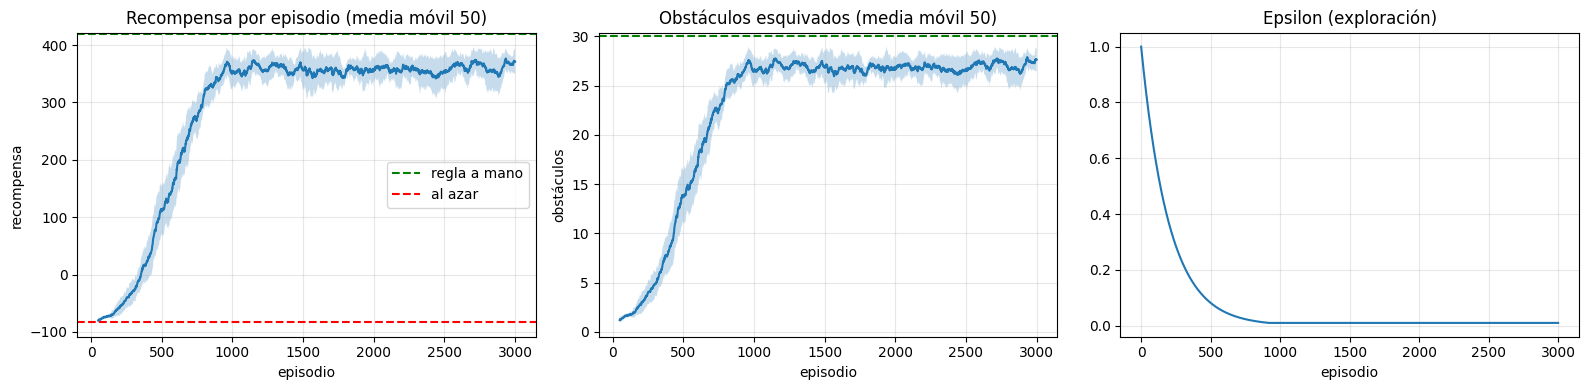

Episodio en que la curva de ENTRENAMIENTO llega al 95 % del tope, por semilla: [958, 1880, 957, 830, 1513, None, 926, 2557, 1450, 958]


In [111]:
SEMILLAS = range(10)                                            # 10 entrenamientos independientes
EPISODIOS_CLAVE = (0, 10, 20, 30, 40, 50, 75, 100, 200, 400, 800, EPISODIOS)   # cuándo guardar copias de Q

corridas = [entrenar(semilla=s, guardar_en=EPISODIOS_CLAVE) for s in SEMILLAS]
agente, hist = corridas[0]            # la corrida 0 es la que usamos para mostrar tabla Q y partidas
historiales = [h for _, h in corridas]


def suavizar(x, ventana=50):
    # Media móvil: promedia cada episodio con los 49 anteriores, para ver la tendencia y no el ruido.
    return np.convolve(x, np.ones(ventana) / ventana, mode="valid")


def curva_con_banda(ax, clave, hists, titulo, ylabel, ventana=50):
    # Dibuja la media entre semillas de una métrica y una banda de ±1 desvío.
    datos = np.array([suavizar(h[clave], ventana) for h in hists])
    x = np.arange(datos.shape[1]) + ventana
    media, desvio = datos.mean(axis=0), datos.std(axis=0)
    ax.plot(x, media)
    ax.fill_between(x, media - desvio, media + desvio, alpha=0.25)
    ax.set_title(titulo); ax.set_xlabel("episodio"); ax.set_ylabel(ylabel); ax.grid(alpha=0.3)


fig, ejes = plt.subplots(1, 3, figsize=(16, 4))
curva_con_banda(ejes[0], "recompensa", historiales, "Recompensa por episodio (media móvil 50)", "recompensa")
ejes[0].axhline(linea_base["regla a mano"]["recompensa"], color="g", ls="--", label="regla a mano")
ejes[0].axhline(linea_base["azar"]["recompensa"], color="r", ls="--", label="al azar")
ejes[0].legend()
curva_con_banda(ejes[1], "esquivados", historiales, "Obstáculos esquivados (media móvil 50)", "obstáculos")
ejes[1].axhline(TOPE_OBSTACULOS, color="g", ls="--")
ejes[2].plot(hist["epsilon"])
ejes[2].set_title("Epsilon (exploración)"); ejes[2].set_xlabel("episodio"); ejes[2].grid(alpha=0.3)
plt.tight_layout(); plt.show()

# Episodio en que la media móvil de ENTRENAMIENTO llega al 95 % del tope.
# Ojo: esto mide cuándo bajó lo suficiente ε, no cuándo aprendió la tabla (eso se ve en la sección 10).
def episodio_de_convergencia(h, umbral=0.95 * TOPE_OBSTACULOS, ventana=50):
    idx = np.where(suavizar(h["esquivados"], ventana) >= umbral)[0]
    return int(idx[0]) + ventana if len(idx) else None

print("Episodio en que la curva de ENTRENAMIENTO llega al 95 % del tope, por semilla:",
      [episodio_de_convergencia(h) for h in historiales])

## 10. Cómo evoluciona el comportamiento del agente

Durante el entrenamiento guardamos copias de la tabla Q. Ahora evaluamos cada copia **sin exploración** (ε = 0) en 500 partidas nuevas. Así se ve cuánto sabe el agente en cada etapa, separado de cuánto explora.

Después mostramos **la misma partida** (misma semilla del entorno) jugada con la tabla en distintos momentos del entrenamiento, para ver el comportamiento cambiar con los ojos:
- con la tabla vacía el agente siempre elige "nada" y choca con el primer cactus,
- con poco entrenamiento acierta algunas decisiones y falla otras,
- con la tabla final salta solo cuando corresponde.

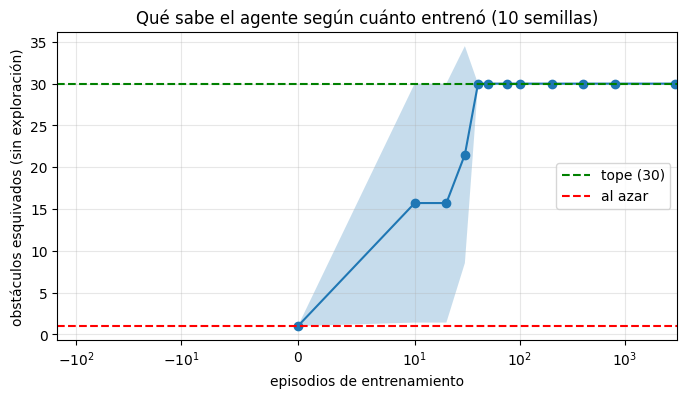

Tras     0 episodios: esquiva  0.98 ± 0.00 de 30
Tras    10 episodios: esquiva 15.71 ± 14.30 de 30
Tras    20 episodios: esquiva 15.71 ± 14.30 de 30
Tras    30 episodios: esquiva 21.51 ± 12.98 de 30
Tras    40 episodios: esquiva 30.00 ± 0.00 de 30
Tras    50 episodios: esquiva 30.00 ± 0.00 de 30
Tras    75 episodios: esquiva 30.00 ± 0.00 de 30
Tras   100 episodios: esquiva 30.00 ± 0.00 de 30
Tras   200 episodios: esquiva 30.00 ± 0.00 de 30
Tras   400 episodios: esquiva 30.00 ± 0.00 de 30
Tras   800 episodios: esquiva 30.00 ± 0.00 de 30
Tras  3000 episodios: esquiva 30.00 ± 0.00 de 30

Agente entrenado (3000 episodios): esquiva 30.00 de 30, recompensa 420.0, llega al tope en 100% de las partidas
Al azar: 1.02 de 30 | Regla a mano: 30 de 30


In [112]:
# --- Gráfico 1: qué tan bueno es el agente según cuánto entrenó (promedio de las 10 semillas)
momentos = list(EPISODIOS_CLAVE)
evolucion = np.array([[evaluar(politica_desde_Q(ag.copias[ep]), 500, semilla=123)["esquivados"] for ep in momentos]
                      for ag, _ in corridas])
media, desvio = evolucion.mean(axis=0), evolucion.std(axis=0)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(momentos, media, marker="o")
ax.fill_between(momentos, media - desvio, media + desvio, alpha=0.25)
ax.axhline(TOPE_OBSTACULOS, color="g", ls="--", label="tope (30)")
ax.axhline(linea_base["azar"]["esquivados"], color="r", ls="--", label="al azar")
ax.set_xscale("symlog", linthresh=10)            # escala log para ver bien los primeros episodios
ax.set_xlabel("episodios de entrenamiento"); ax.set_ylabel("obstáculos esquivados (sin exploración)")
ax.set_title("Qué sabe el agente según cuánto entrenó (10 semillas)"); ax.legend(); ax.grid(alpha=0.3)
plt.show()
for ep, m, d in zip(momentos, media, desvio):
    print(f"Tras {ep:5d} episodios: esquiva {m:5.2f} ± {d:4.2f} de 30")

# --- Resultado final contra las líneas base (1000 partidas nuevas por semilla, sin exploración)
finales = [evaluar(ag.politica, 1000, semilla=999) for ag, _ in corridas]
print(f"\nAgente entrenado ({EPISODIOS} episodios): esquiva {np.mean([f['esquivados'] for f in finales]):.2f} de 30, "
      f"recompensa {np.mean([f['recompensa'] for f in finales]):.1f}, "
      f"llega al tope en {np.mean([f['tasa_tope'] for f in finales]):.0%} de las partidas")
print(f"Al azar: {linea_base['azar']['esquivados']:.2f} de 30 | Regla a mano: {linea_base['regla a mano']['esquivados']:.0f} de 30")

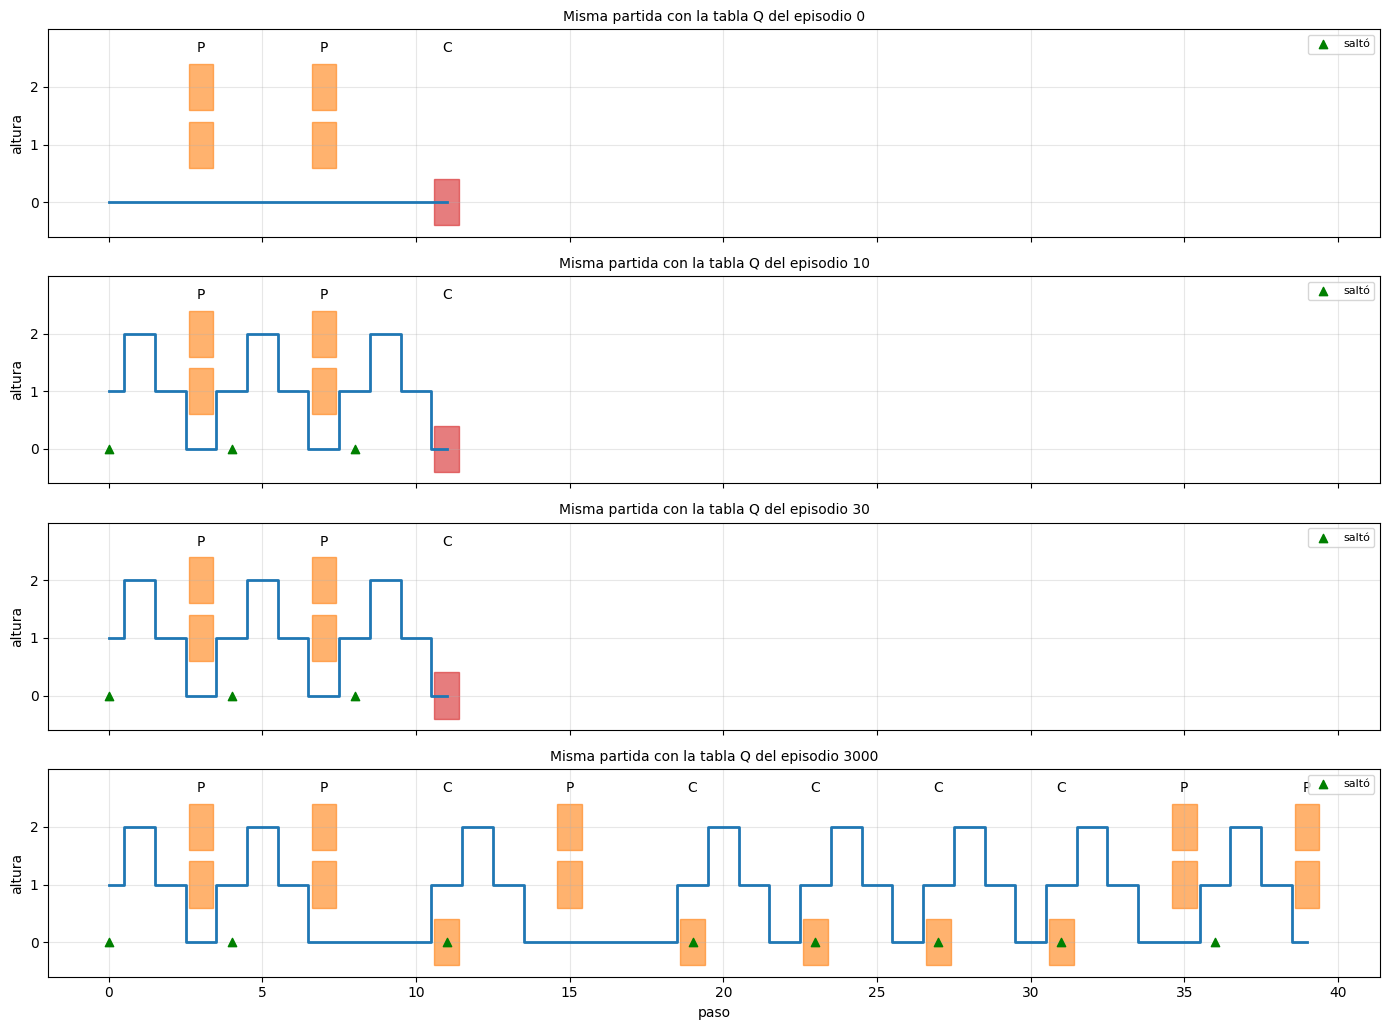

In [113]:
def linea_de_tiempo(ax, politica, semilla, titulo, pasos_a_mostrar=40, recompensas=RECOMPENSAS):
    # Dibuja un episodio como línea de tiempo: la línea azul es la altura del dino y los bloques
    # son los obstáculos en el momento en que llegan a la columna 0 (naranja = esquivado, rojo = choque).
    alturas, llegadas, acciones, _ = grabar_episodio(politica, semilla, recompensas=recompensas)
    n = min(len(alturas), pasos_a_mostrar)
    ax.step(range(n), alturas[:n], where="mid", color="tab:blue", lw=2)
    for paso, tipo, evento in llegadas:
        if paso >= n:
            continue
        for h in OCUPA[tipo]:
            ax.add_patch(Rectangle((paso - 0.4, h - 0.4), 0.8, 0.8,
                                   color="tab:red" if evento == "choque" else "tab:orange", alpha=0.6))
        ax.text(paso, 2.6, "C" if tipo == CACTUS else "P", ha="center")   # tipo de obstáculo
    # Triángulo verde en cada salto real (acción SALTAR estando en el suelo)
    saltos = [i for i in range(n) if acciones[i] == SALTAR and (i == 0 or alturas[i - 1] == 0)]
    ax.scatter(saltos, [0] * len(saltos), marker="^", color="green", zorder=5, label="saltó")
    ax.set_yticks([0, 1, 2]); ax.set_ylim(-0.6, 3); ax.set_ylabel("altura")
    ax.set_title(titulo, fontsize=10); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)


# --- Gráfico 2: la misma partida con la tabla del episodio 0, 10, 30 y final
etapas = [0, 10, 30, EPISODIOS]
fig, ejes = plt.subplots(len(etapas), 1, figsize=(14, 2.6 * len(etapas)), sharex=True)
for ax, ep in zip(ejes, etapas):
    linea_de_tiempo(ax, politica_desde_Q(agente.copias[ep]), semilla=5,
                    titulo=f"Misma partida con la tabla Q del episodio {ep}")
ejes[-1].set_xlabel("paso")
plt.tight_layout(); plt.show()

## 11. Tabla Q y política aprendida

Las decisiones reales ocurren solo en los **8 estados con el dino en el suelo** (fase 0): 4 distancias × 2 tipos de obstáculo. En el aire ninguna acción cambia nada, así que sus filas de la tabla Q valen lo mismo para las dos acciones.

Abajo: la tabla Q de esos 8 estados con la política resultante, un mapa de calor con la ventaja de saltar `Q(saltar) − Q(nada)`, y el valor `max Q` de los 32 estados.

**Cómo leerlo.**
- Para el **cactus** hay tres distancias válidas para saltar (1, 2 y 3): cualquiera funciona, así que la política puede elegir saltar en cualquiera. Saltar a distancia 4 es un error porque el dino aterriza justo cuando llega el cactus.
- Para el **pájaro**, saltar a distancia 1, 2 o 3 es siempre un error. A distancia 4 da igual (el dino ya aterrizó cuando llega), por eso ahí la ventaja es ≈ 0.
- La política aprendida no tiene por qué ser igual a la regla a mano, pero sí debe rendir igual. Lo verificamos con la tasa de partidas que llegan al tope, no comparando tablas.

obstáculo  dist   Q(nada)  Q(saltar)  política  visitas
cactus        4     346.2      -94.0  nada        18879
cactus        3     348.7      329.4  nada        18731
cactus        2     351.2      321.6  nada        18604
cactus        1    -100.0      353.8  saltar      35679
pájaro        4     346.1      346.2  saltar      18766
pájaro        3     348.7      -57.7  nada          369
pájaro        2     351.2      -68.7  nada          420
pájaro        1     353.8     -100.0  nada        17375


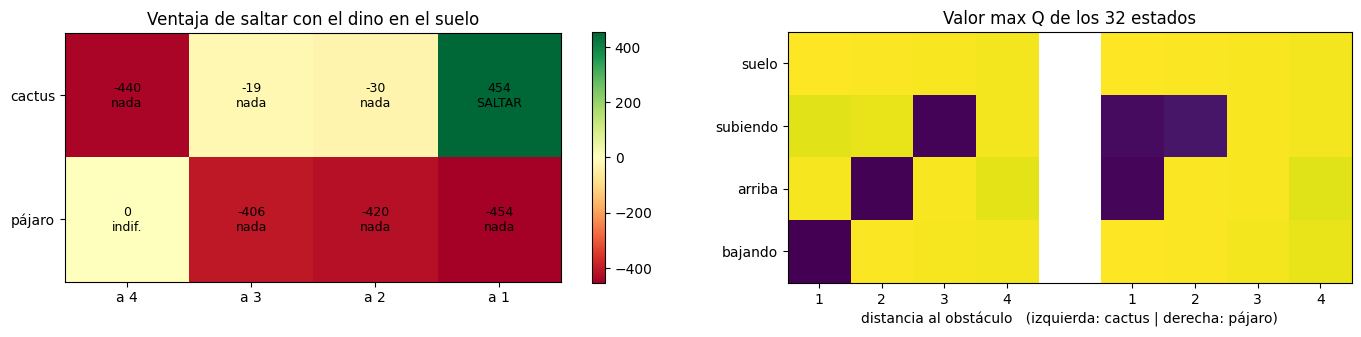

Semillas cuya política llega al tope en el 100 % de las partidas: 10 de 10
Mínimo de visitas a una celda de decisión (acción menos probada): 38


In [114]:
# --- Tabla de las 8 decisiones con el dino en el suelo
print(f"{'obstáculo':10s} {'dist':>4s} {'Q(nada)':>9s} {'Q(saltar)':>10s}  {'política':8s} {'visitas':>8s}")
for tipo in (CACTUS, PAJARO):
    for d in (4, 3, 2, 1):
        s = estado_a_indice((0, d, tipo))
        print(f"{NOMBRE_TIPO[tipo]:10s} {d:4d} {agente.Q[s, NADA]:9.1f} {agente.Q[s, SALTAR]:10.1f}  "
              f"{NOMBRE_ACCION[agente.mejor_accion((0, d, tipo))]:8s} {agente.visitas[s].sum():8d}")

# --- Mapa de calor: ventaja de saltar = Q(saltar) - Q(nada). Verde: conviene saltar. Rojo: conviene no saltar.
ventaja = np.zeros((2, 4))
for tipo in (CACTUS, PAJARO):
    for j, d in enumerate((4, 3, 2, 1)):
        s = estado_a_indice((0, d, tipo))
        ventaja[tipo, j] = agente.Q[s, SALTAR] - agente.Q[s, NADA]

fig, ejes = plt.subplots(1, 2, figsize=(14, 3.2))
lim = np.abs(ventaja).max()
im = ejes[0].imshow(ventaja, cmap="RdYlGn", vmin=-lim, vmax=lim)
ejes[0].set_xticks(range(4)); ejes[0].set_xticklabels(["a 4", "a 3", "a 2", "a 1"])
ejes[0].set_yticks([0, 1]); ejes[0].set_yticklabels(["cactus", "pájaro"])
for i in range(2):
    for j in range(4):
        etiqueta = "indif." if abs(ventaja[i, j]) < 1 else "SALTAR" if ventaja[i, j] > 0 else "nada"
        ejes[0].text(j, i, f"{ventaja[i, j]:.0f}\n{etiqueta}", ha="center", va="center", fontsize=9)
ejes[0].set_title("Ventaja de saltar con el dino en el suelo")
plt.colorbar(im, ax=ejes[0])

# --- Valor de cada uno de los 32 estados: max Q. Filas = fase, columnas = distancia. Una grilla por tipo.
V = np.zeros((2, 4, 4))
for i in range(N_ESTADOS):
    fase, d, tipo = indice_a_estado(i)
    V[tipo, fase, d - 1] = agente.Q[i].max()
ejes[1].imshow(np.hstack([V[CACTUS], np.full((4, 1), np.nan), V[PAJARO]]), cmap="viridis")
ejes[1].set_xticks([0, 1, 2, 3, 5, 6, 7, 8]); ejes[1].set_xticklabels(["1", "2", "3", "4"] * 2)
ejes[1].set_yticks(range(4)); ejes[1].set_yticklabels(["suelo", "subiendo", "arriba", "bajando"])
ejes[1].set_xlabel("distancia al obstáculo   (izquierda: cactus | derecha: pájaro)")
ejes[1].set_title("Valor max Q de los 32 estados")
plt.tight_layout(); plt.show()

# --- ¿La política aprendida nunca choca? Contamos las semillas con 100 % de partidas perfectas
perfectas = sum(f["tasa_tope"] == 1.0 for f in finales)
print(f"Semillas cuya política llega al tope en el 100 % de las partidas: {perfectas} de {len(finales)}")

# --- ¿Se visitaron todas las celdas de decisión? (si no, la tabla ahí no está respaldada por datos)
visitas_decision = [agente.visitas[estado_a_indice((0, d, t))].min() for t in (CACTUS, PAJARO) for d in (4, 3, 2, 1)]
print(f"Mínimo de visitas a una celda de decisión (acción menos probada): {min(visitas_decision)}")

## 12. Movimientos del agente

El agente entrenado jugando una partida, dibujado de dos formas:
1. **Fotogramas**: la grilla paso a paso, con el dino, el obstáculo y la acción elegida.
2. **Línea de tiempo** de un episodio largo, contra la de un agente al azar con la misma partida (la secuencia de obstáculos es la misma porque usan la misma semilla del entorno).

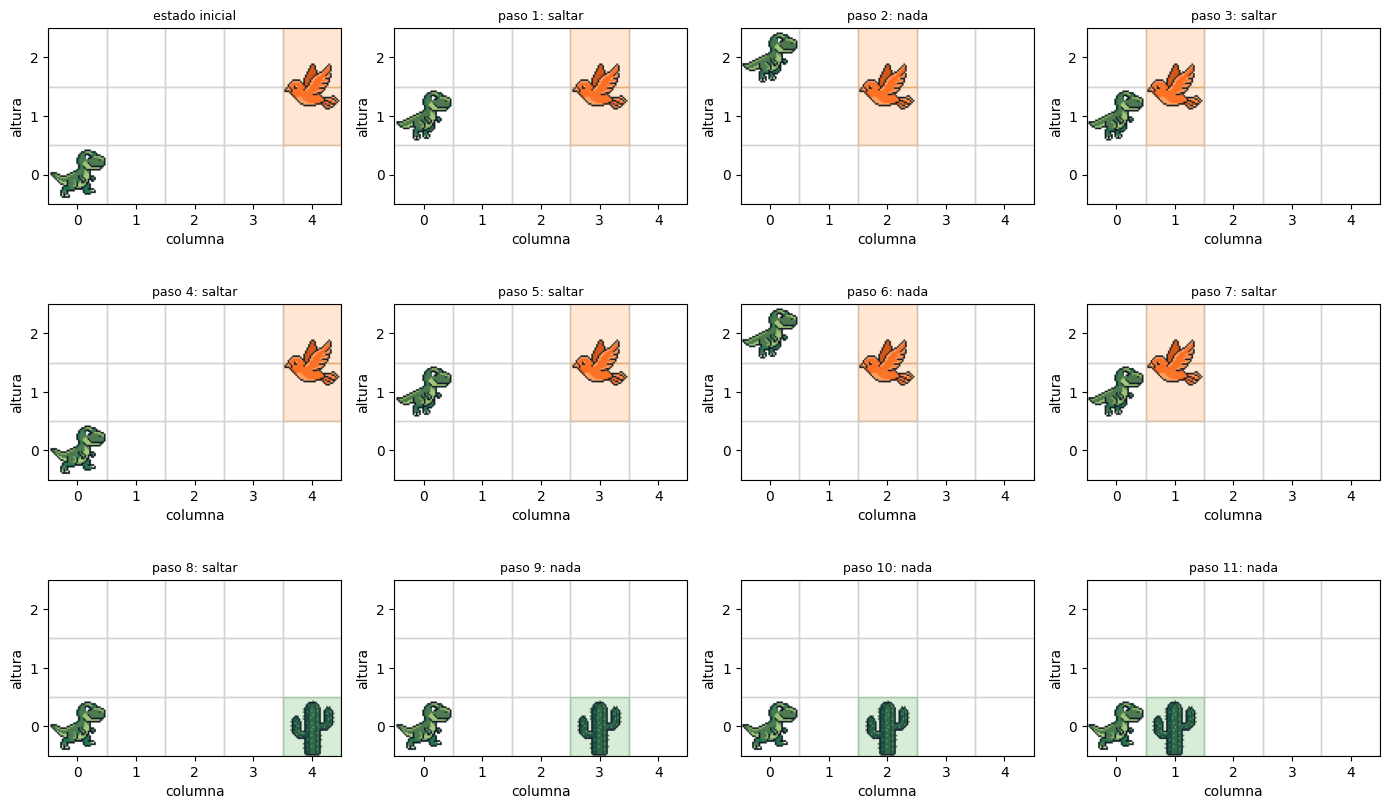

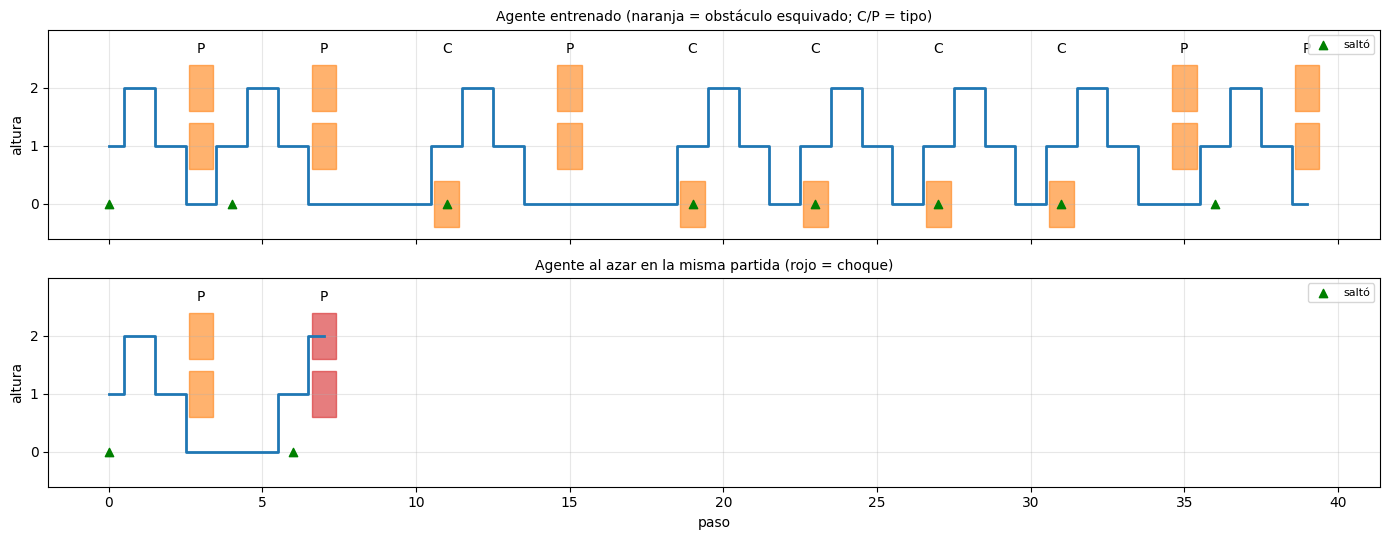

In [115]:
# --- Fotogramas: primeros pasos de una partida con la política aprendida
_, llegadas, acciones, estados = grabar_episodio(agente.politica, semilla=5, max_pasos=12)
fig, ejes = plt.subplots(3, 4, figsize=(14, 8.5))
for k, ax in enumerate(ejes.flat):
    if k < len(estados):
        titulo = "estado inicial" if k == 0 else f"paso {k}: {NOMBRE_ACCION[acciones[k - 1]]}"
        n_obs = sum(1 for paso, _, ev in llegadas if ev == "esquivó" and paso < k)   # obstáculos esquivados hasta este cuadro
        dibujar_fotograma(ax, estados[k], titulo=titulo, n_obstaculo=n_obs)
    else:
        ax.axis("off")
plt.tight_layout(); plt.show()

# --- Línea de tiempo: agente entrenado vs. al azar, misma partida
fig, ejes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
linea_de_tiempo(ejes[0], agente.politica, semilla=5, titulo="Agente entrenado (naranja = obstáculo esquivado; C/P = tipo)")
azar = random.Random(7)   # se reinicia el generador del agente al azar para que el resultado sea repetible
linea_de_tiempo(ejes[1], politica_azar, semilla=5, titulo="Agente al azar en la misma partida (rojo = choque)")
ejes[1].set_xlabel("paso")
plt.tight_layout(); plt.show()

## 13. Cambiando la función de recompensa

La recompensa es lo único que le dice al agente qué queremos. Entrenamos el mismo agente (mismos α, γ, ε, episodios y semillas) con cuatro funciones distintas y medimos qué hace con cada una. Lo único que cambia entre experimentos es la recompensa.

| Configuración | paso | esquivar | choque | Qué queremos ver |
|---|---|---|---|---|
| Base (Entrega 1) | +1 | +10 | −100 | Referencia |
| Solo castigo | 0 | 0 | −100 | ¿Alcanza con castigar el choque? (recompensa dispersa) |
| Castigo débil | +1 | +10 | −5 | ¿Qué pasa si chocar casi no cuesta? |
| Costo de vivir | −1 | +2 | −5 | Cada paso cuesta más de lo que se gana: ¿conviene morir pronto? |

**Hipótesis antes de correrlo:**
- *Solo castigo*: debería aprender igual, porque el único evento que distingue buenas de malas decisiones es el choque.
- *Castigo débil*: también debería aprender, porque chocar corta todas las ganancias futuras de +1 y +10 por obstáculo, aunque el choque en sí cueste poco.
- *Costo de vivir*: con `paso = −1` y `esquivar = +2`, esquivar un obstáculo (4 pasos) deja **−2** neto, y chocar al principio cuesta como mucho −8. A este agente le conviene terminar rápido: es el clásico *reward hacking* (optimiza lo que pedimos, no lo que quisimos pedir).

Las métricas son siempre de la partida real (obstáculos esquivados y pasos vividos), no de la recompensa, porque esa cambia de escala entre configuraciones.

configuración    esquiva (de 30)  tasa de tope  pasos vividos
Base                 30.00 ±  0.0          100%          120.0
Solo castigo         30.00 ±  0.0          100%          120.0
Castigo débil        30.00 ±  0.0          100%          120.0
Costo de vivir        0.00 ±  0.0            0%            4.0


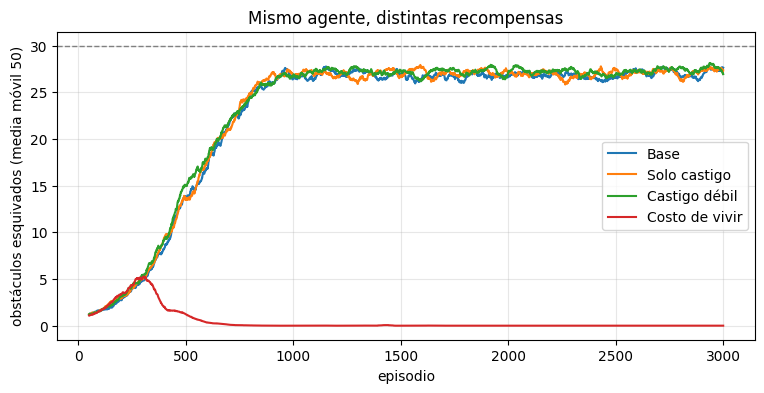


configuración   C@4 C@3 C@2 C@1 P@4 P@3 P@2 P@1
Base             nada  nada  nada SALTA SALTA  nada  nada  nada
Solo castigo     nada  nada  nada SALTA  nada  nada  nada  nada
Castigo débil    nada SALTA SALTA SALTA SALTA  nada  nada  nada
Costo de vivir  SALTA  nada  nada  nada  nada  nada  nada SALTA


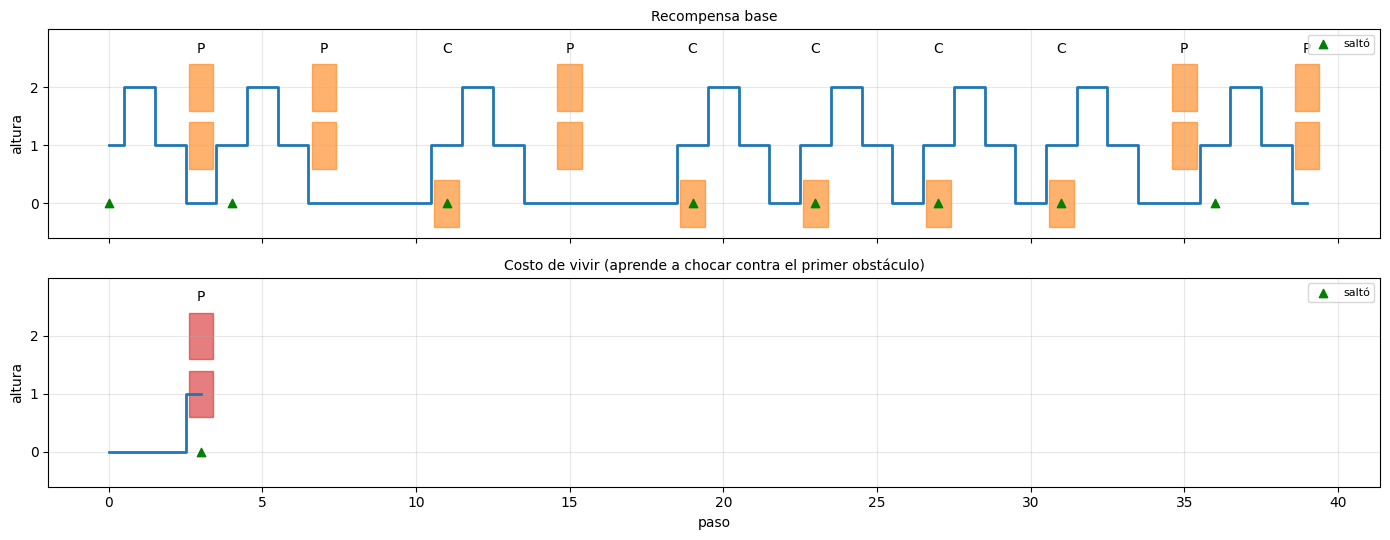

In [116]:
CONFIGS = {
    "Base":           {"paso": 1,  "esquivar": 10, "choque": -100},
    "Solo castigo":   {"paso": 0,  "esquivar": 0,  "choque": -100},
    "Castigo débil":  {"paso": 1,  "esquivar": 10, "choque": -5},
    "Costo de vivir": {"paso": -1, "esquivar": 2,  "choque": -5},
}

resultados_cfg, hist_cfg, agentes_cfg = {}, {}, {}
for nombre, rec in CONFIGS.items():
    corr = [entrenar(rec, semilla=s) for s in SEMILLAS]                    # 10 entrenamientos por configuración
    # Se evalúa con la MISMA función de recompensa con que se entrenó (sin exploración, 500 partidas)
    resultados_cfg[nombre] = [evaluar(ag.politica, 500, semilla=999, recompensas=rec) for ag, _ in corr]
    hist_cfg[nombre] = [h for _, h in corr]
    agentes_cfg[nombre] = corr[0][0]                                       # nos quedamos con el de la semilla 0

# --- Tabla de resultados
print(f"{'configuración':15s} {'esquiva (de 30)':>16s} {'tasa de tope':>13s} {'pasos vividos':>14s}")
for nombre, ev in resultados_cfg.items():
    print(f"{nombre:15s} {np.mean([e['esquivados'] for e in ev]):10.2f} ± {np.std([e['esquivados'] for e in ev]):4.1f} "
          f"{np.mean([e['tasa_tope'] for e in ev]):13.0%} {np.mean([e['pasos'] for e in ev]):14.1f}")

# --- Curvas de aprendizaje de las cuatro configuraciones
fig, ax = plt.subplots(figsize=(9, 4))
for nombre, hs in hist_cfg.items():
    datos = np.array([suavizar(h["esquivados"], 50) for h in hs])
    ax.plot(np.arange(datos.shape[1]) + 50, datos.mean(axis=0), label=nombre)
ax.axhline(TOPE_OBSTACULOS, color="gray", ls="--", lw=1)
ax.set_xlabel("episodio"); ax.set_ylabel("obstáculos esquivados (media móvil 50)")
ax.set_title("Mismo agente, distintas recompensas"); ax.legend(); ax.grid(alpha=0.3)
plt.show()

# --- Política resultante en las 8 decisiones, para cada configuración (C = cactus, P = pájaro, @n = distancia)
print()
print(f"{'configuración':15s} " + " ".join(f"{NOMBRE_TIPO[t][0].upper()}@{d}" for t in (CACTUS, PAJARO) for d in (4, 3, 2, 1)))
for nombre, ag in agentes_cfg.items():
    celdas = ["SALTA" if ag.mejor_accion((0, d, t)) == SALTAR else "nada" for t in (CACTUS, PAJARO) for d in (4, 3, 2, 1)]
    print(f"{nombre:15s} " + " ".join(f"{c:>5s}" for c in celdas))

# --- El comportamiento "suicida" a la vista: misma partida con la política de Base y de Costo de vivir
fig, ejes = plt.subplots(2, 1, figsize=(14, 5.5), sharex=True)
linea_de_tiempo(ejes[0], agentes_cfg["Base"].politica, semilla=5, titulo="Recompensa base")
linea_de_tiempo(ejes[1], agentes_cfg["Costo de vivir"].politica, semilla=5,
                titulo="Costo de vivir (aprende a chocar contra el primer obstáculo)", recompensas=CONFIGS["Costo de vivir"])
ejes[1].set_xlabel("paso")
plt.tight_layout(); plt.show()

## 14. Sensibilidad a α, γ y ε

Variamos un hiperparámetro por vez, dejando el resto en los valores iniciales, con la recompensa base y 10 semillas.
Como la política ya es perfecta después de pocas decenas de episodios (sección 10), comparamos con un presupuesto chico: **100 episodios de entrenamiento**. La métrica es cuánto esquiva el agente después, sin explorar, y en cuántas de las 10 semillas llega siempre al tope.

In [117]:
def barrido(nombre, valores, semillas=range(10), episodios=100):
    # Entrena 10 agentes por cada valor del hiperparámetro y mide cómo juegan sin explorar.
    filas = []
    for v in valores:
        ev = [evaluar(entrenar(semilla=s, episodios=episodios, **{nombre: v})[0].politica, 300, semilla=999)
              for s in semillas]
        filas.append((v, np.mean([e["esquivados"] for e in ev]), sum(e["tasa_tope"] == 1.0 for e in ev)))
    return filas


for nombre, valores in {"alfa": [0.01, 0.1, 0.5], "gamma": [0.0, 0.5, 0.99], "decaimiento": [0.95, 0.99, 0.995, 0.999]}.items():
    print(f"\n{nombre} (100 episodios de entrenamiento)")
    print(f"{'valor':>8s} {'esquiva (sin explorar)':>23s} {'semillas perfectas':>19s}")
    for v, esq, perfectas in barrido(nombre, valores):
        print(f"{v:8} {esq:23.2f} {perfectas:15d}/10")


alfa (100 episodios de entrenamiento)
   valor  esquiva (sin explorar)  semillas perfectas
    0.01                   12.56               4/10
     0.1                   30.00              10/10
     0.5                   30.00              10/10

gamma (100 episodios de entrenamiento)
   valor  esquiva (sin explorar)  semillas perfectas
     0.0                    6.81               2/10
     0.5                   30.00              10/10
    0.99                   30.00              10/10

decaimiento (100 episodios de entrenamiento)
   valor  esquiva (sin explorar)  semillas perfectas
    0.95                   30.00              10/10
    0.99                   30.00              10/10
   0.995                   30.00              10/10
   0.999                   30.00              10/10


### 14.1 ¿Las mejoras hacen que aprenda más?

Comparamos el agente base con cada mejora de la sección 8.1 por separado y con las cinco juntas. Mismo entorno, misma recompensa, 3000 episodios y 10 semillas por variante. En varios momentos del entrenamiento medimos dos cosas:

- **Qué tan bien juega**: obstáculos esquivados sin explorar (100 partidas nuevas). Mide la *política*.
- **Cuánto de la tabla aprendió**: celdas bien aprendidas de las 64 (a menos del 5 % del valor real `Q*`). Mide los *valores*.

Son dos cosas distintas: un agente puede jugar perfecto con una tabla a medio aprender, porque para decidir alcanza con que la acción correcta valga más que la otra, no con que valga lo justo. Tarda alrededor de un minuto.

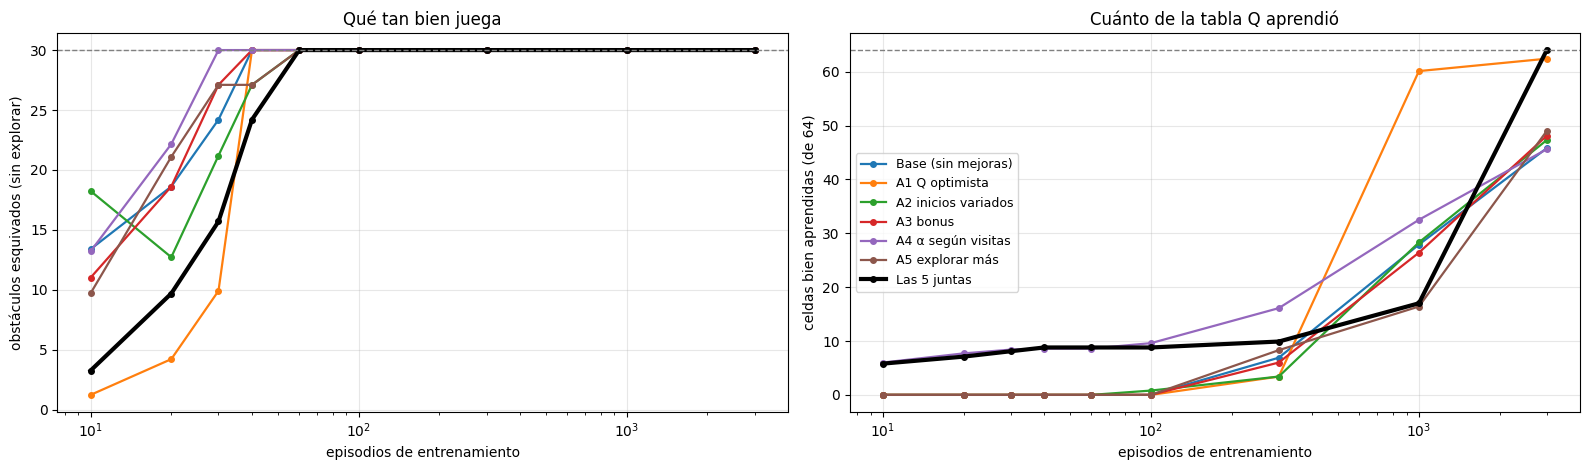

variante                juega perfecto desde   celdas bien (de 64) tras 100 / 300 / 1000 / 3000 episodios
Base (sin mejoras)             ~22 episodios                                  0.0     6.9    27.9    45.8
A1 Q optimista                 ~36 episodios                                  0.0     3.4    60.1    62.4
A2 inicios variados            ~21 episodios                                  0.8     3.4    28.3    47.3
A3 bonus                       ~22 episodios                                  0.0     6.0    26.4    48.1
A4 α según visitas             ~19 episodios                                  9.6    16.1    32.5    45.6
A5 explorar más                ~21 episodios                                  0.0     8.3    16.4    49.0
Las 5 juntas                   ~35 episodios                                  8.8     9.9    17.0    64.0


In [118]:
VARIANTES = {
    "Base (sin mejoras)":   {},
    "A1 Q optimista":       {"q_inicial": MEJORAS["q_inicial"]},
    "A2 inicios variados":  {"inicio_variado": True},
    "A3 bonus":             {"bonus": MEJORAS["bonus"]},
    "A4 α según visitas":   {"alfa_por_visitas": True},
    "A5 explorar más":      {"eps_min": MEJORAS["eps_min"], "decaimiento": MEJORAS["decaimiento"]},
    "Las 5 juntas":         MEJORAS,
}
MOMENTOS_MEJORAS = (10, 20, 30, 40, 60, 100, 300, 1000, 3000)   # episodios en los que se mide


def seguir_variante(opciones, semilla, momentos=MOMENTOS_MEJORAS):
    # Entrena un agente con esas mejoras y, en cada momento, mide cómo juega y cuánto de la tabla aprendió.
    env, agente = crear_entorno_y_agente(semilla, **opciones)
    esquiva, bien = [], []
    for ep in range(1, max(momentos) + 1):
        jugar_y_aprender(env, agente)
        agente.fin_episodio()
        if ep in momentos:
            esquiva.append(evaluar(agente.politica, 100, semilla=999)["esquivados"])
            bien.append(celdas_bien_aprendidas(agente.Q))
    return esquiva, bien


res_mejoras = {}
for nombre, opciones in VARIANTES.items():
    datos = np.array([seguir_variante(opciones, s) for s in SEMILLAS])   # forma: (semillas, 2 métricas, momentos)
    res_mejoras[nombre] = {"esquiva": datos[:, 0], "bien": datos[:, 1]}

# --- Gráficos: cómo juega (izquierda) y cuánto de la tabla aprendió (derecha)
fig, ejes = plt.subplots(1, 2, figsize=(16, 4.8))
for nombre, r in res_mejoras.items():
    estilo = {"lw": 3, "color": "black"} if nombre == "Las 5 juntas" else {"lw": 1.6}
    ejes[0].plot(MOMENTOS_MEJORAS, r["esquiva"].mean(axis=0), marker="o", ms=4, label=nombre, **estilo)
    ejes[1].plot(MOMENTOS_MEJORAS, r["bien"].mean(axis=0), marker="o", ms=4, label=nombre, **estilo)
ejes[0].axhline(TOPE_OBSTACULOS, color="gray", ls="--", lw=1)
ejes[0].set_ylabel("obstáculos esquivados (sin explorar)"); ejes[0].set_title("Qué tan bien juega")
ejes[1].axhline(2 * N_ESTADOS, color="gray", ls="--", lw=1)
ejes[1].set_ylabel("celdas bien aprendidas (de 64)"); ejes[1].set_title("Cuánto de la tabla Q aprendió")
for ax in ejes:
    ax.set_xscale("log"); ax.set_xlabel("episodios de entrenamiento"); ax.grid(alpha=0.3)
ejes[1].legend(fontsize=9)
plt.tight_layout(); plt.show()

# --- Tabla resumen (promedio de 10 semillas)
def primer_episodio_perfecto(esquiva):
    # Primer momento en que la política sin exploración esquiva los 30 (en esa semilla)
    return next((m for m, v in zip(MOMENTOS_MEJORAS, esquiva) if v == TOPE_OBSTACULOS), None)

print(f"{'variante':22s} {'juega perfecto desde':>21s} {'celdas bien (de 64) tras 100 / 300 / 1000 / 3000 episodios':>60s}")
for nombre, r in res_mejoras.items():
    desde = [primer_episodio_perfecto(e) for e in r["esquiva"]]
    desde_txt = f"~{np.mean(desde):.0f} episodios" if None not in desde else "no siempre"
    bien = r["bien"].mean(axis=0)
    cols = "   ".join(f"{bien[MOMENTOS_MEJORAS.index(m)]:5.1f}" for m in (100, 300, 1000, 3000))
    print(f"{nombre:22s} {desde_txt:>21s} {cols:>60s}")

**Qué muestra el experimento** (promedio de 10 semillas; los números salen de la tabla de arriba):

- **Jugar bien** lo logran todas: tras 3000 episodios todas las variantes esquivan los 30 obstáculos sin explorar. Lo que cambia es *cuándo*. **A4** llega un poco antes que la base (~19 contra ~22 episodios) porque en la primera visita usa α = 1 y un choque baja de golpe el valor de la acción que lo causó. **A1** tarda más (~36): al principio todas las acciones "parecen buenas" y el agente se dedica a probarlas. Las 5 juntas, ~35.
- **Aprender toda la tabla** es otra historia. El agente base termina con ~46 de 64 celdas bien aprendidas: el resto queda lejos de su valor real (por ejemplo, saltar con un cactus a distancia 2 o 3 vale ≈ 350 y la base lo deja en ≈ 320-330, porque casi nunca lo hace). **A1** es la mejora que más ayuda sola (~62 de 64). **Las 5 juntas llegan a 64 de 64**: la tabla entera coincide con `Q*`. A mitad de camino (1000 episodios) van más lento que A1 sola, porque A5 las hace seguir explorando, pero terminan completas.
- **A4** es la que más aprende **al principio** (~10 celdas bien a los 100 episodios contra 0 de la base), pero sola no completa la tabla.
- **A2, A3 y A5** por separado cambian poco (47 a 49 celdas contra 46): a la base no le falta *visitar* las celdas (con ε arrancando en 1 visita todo), le falta que sus valores se *propaguen*. Combinadas con A1 y A4 ayudan a que las celdas raras se sigan corrigiendo.
- **Por qué no usamos α = 1/N puro en A4.** Con α = 1/N el agente promedia todo lo que vio desde el principio, incluidos los objetivos de cuando la tabla todavía estaba mal. Los pasos se achican tan rápido que la tabla queda clavada lejos de `Q*` (lo probamos: ~3 celdas bien de 64 tras 3000 episodios, mucho peor que la base). Con un piso de α = 0,1 conserva lo bueno de los pasos grandes al principio y sigue corrigiendo después.

**Relación con el problema.** Para *jugar* al dinosaurio alcanza con el agente base. Las mejoras importan si queremos que el agente **sepa cuánto vale cada situación**, no solo qué hacer: por ejemplo, para que una situación que nunca ve (un cactus a distancia 1 con el dino en el suelo) tenga un valor correcto si algún día aparece.

## 15. Conclusiones

Los números salen de correr este notebook con las semillas fijas (0 a 9). Si se cambian las semillas o los parámetros, hay que revisarlos.

- **Aprendizaje.** El agente al azar esquiva ≈ 1 obstáculo de 30. Con Q-Learning, la política sin exploración llega a esquivar los 30 en el 100 % de las partidas, en las 10 semillas, a partir de ~40 episodios (a los 30 todavía esquiva ≈ 21,5 ± 13 de 30). La curva de entrenamiento sube mucho más lento (≈ 1000 episodios) y se queda cerca de 27 porque incluye la exploración: ε sigue alto cuando la tabla ya es perfecta.
- **Política.** Con cactus salta a distancia 1 (también sirven 2 y 3) y nunca a distancia 4; con pájaro no salta a distancia 1, 2 ni 3. A distancia 4 con pájaro da igual. La política aprendida puede diferir de la regla a mano y rendir igual.
- **Recompensa.** Con la base, con solo castigo por choque y con castigo débil (−5), el agente aprende a esquivar todo, porque seguir vivo ya vale más que cualquier choque; solo cambia *dónde* salta cuando es indiferente. Con costo de vivir (paso −1, esquivar +2, choque −5) aprende a chocar contra el primer obstáculo (4 pasos de vida): maximiza lo que le pedimos, no lo que queríamos. La función de recompensa define el comportamiento tanto como el algoritmo.
- **Hiperparámetros.** α = 0,01 es demasiado lento para 100 episodios (4 de 10 semillas perfectas); α = 0,1 y 0,5 alcanzan. γ = 0 **falla** (2 de 10 semillas): sin descuento el agente no ve que saltar a distancia 4 con cactus, o saltar con pájaro a distancia 2 o 3, termina en choque unos pasos después. Esto confirma por qué γ alto es necesario. El decaimiento de ε casi no importa a 100 episodios porque Q-Learning aprende la política greedy aun explorando (es *off-policy*).
- **Mejoras de exploración (8.1 y 14.1).** Jugar perfecto no es lo mismo que aprender toda la tabla: el agente base juega perfecto en ~40 episodios pero tras 3000 tiene ~46 de las 64 celdas de la tabla Q cerca de su valor real `Q*`. Con las cinco mejoras juntas (Q inicial optimista, inicios variados, bonus por exploración, α según visitas y explorar más tiempo) llega a 64 de 64. La que más aporta sola es la Q inicial optimista (~62 de 64). α = 1/N puro empeora el aprendizaje; con un piso de 0,1 acelera el principio.
- **Relación con el problema.** El dinosaurio es un problema donde nadie da respuestas etiquetadas, las decisiones son secuenciales y el castigo llega con demora: justo el tipo de problema para el que sirve el aprendizaje por refuerzo.
- **Limitaciones.** El entorno es chico y casi determinístico (solo es aleatorio el tipo del próximo obstáculo), por eso una tabla lo resuelve por completo y el aprendizaje termina rápido. Un paso siguiente sería agregar velocidad variable o separación aleatoria entre obstáculos para que haya decisiones menos triviales.